In [1]:
import json
import joblib
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pathlib import Path
from glob import glob
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

import config
from utils.data import load_dataset
from experiments.modelconfig import ablation_study
from utils.plotting import df_to_gridded_da, plot_geo_panels, generate_latex_table


C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
sns.set_theme(style="whitegrid")

In [3]:
model_name = "mastnet"
ablation_base_dir = Path("D:/phd/output/tuning/mastnet/architecture_ablation/")

# Metrics
min_metrics = ["MAE", "RMSE", "NRMSE"]
max_metrics = ["R2", "PCC", "KGE", "OI"]
metrics_to_plot = ["Total time", "RMSE", "CMIP_diff", "WOA_diff"]

# Valid experiment ids
masking_exp_ids = ["exp" + str(i) for i in range(53, 70)] + ["exp86"]
per_sample_num_map = {0.3: 1, 0.4: 2, 0.5: 3, 0.7: 4, 0.9: 5}

# Plotting utils
attention_name_map = {
    "space_time_attention": "Space-time attention",
    "mha": "Cross-attention",
    "autoencoder": "Autoencoder",
    "encoder_decoder": "Autoencoder",
    "space_time_depth_attention": "Space-time-depth attention",
    "transformer_encoder_layer": "Joint attention",
    "transformer_encoder": "Joint attention",
    "time_space_attention": "Time space attention",
}

models_palette = sorted(["Cross-attention", "Joint attention", "Autoencoder",
                         "Space-time attention", "Space-time-depth attention",
                         "Time space attention"])
palette = dict(zip(models_palette, sns.color_palette("tab10", n_colors=len(models_palette))))


In [4]:
# Load data
df = load_dataset()
baseline_cfg = ablation_study["exp0"]["config"]
test_idx = json.load(open(f"{config.output_dir_splits}/test_train_split.json", "r"))["test_idx"]

In [5]:
def get_attr(res, attr_name):
    """Get attribute form hyps.model.cfg entry of the results object."""
    if attr_name in res["hyps"]["model"]["cfg"].keys():
        return res["hyps"]["model"]["cfg"][attr_name]
    else:
        return getattr(baseline_cfg, attr_name)


def load_experiment(dir_path, model_name="mastnet", woa=True, cmip=True):
    """Load an experiment from a directory path."""
    df_woa, df_cmip = [], []

    file_path = Path(dir_path) / f"model{model_name}_splitfinal_trial0.json"
    if not Path(file_path).is_file():
        print(f"No such file: {file_path}")
        return None, None, None
    res = json.load(open(file_path, "r"))
    metrics_field = "test_metrics" if res["model_framework"] == "pytorch" else "metrics_all"
    metrics = pd.DataFrame([res[metrics_field]["Global"]])
    exp_id = dir_path.parts[-1]
    metrics["exp_id"] = exp_id

    if "model" in res["hyps"].keys():
        if "cfg" in res["hyps"]["model"].keys():
            metrics["mask_ratio"] = get_attr(res, "mask_ratio")
            metrics["transect_mask_orientation"] = get_attr(res, "transect_mask_orientation")
            metrics["sphere_mask_radius"] = get_attr(res, "sphere_mask_radius")
            metrics["masking_strategies"] = str(get_attr(res, "masking_strategies"))
            metrics["transect_mask_width"] = str(get_attr(res, "transect_mask_width"))

    if woa:
        # Load WOA comparison
        woa_path = dir_path / f"{model_name}_woa_diff_summary_scaled.csv"
        if not woa_path.is_file():
            raise FileNotFoundError(f"No such file: {woa_path}")
        w = pd.read_csv(woa_path)
        w["exp_id"] = exp_id
        df_woa.append(w)
        metrics["WOA_diff"] = w["MAE"].mean()
        metrics["WOA_std"] = w["std"].mean()

    if cmip:
        # Load CMIP comparison
        cmip_path = dir_path / f"{model_name}_cmip_diff_summary_scaled.csv"
        if not cmip_path.is_file():
            raise FileNotFoundError(f"No such file: {cmip_path}")
        c = pd.read_csv(cmip_path)
        c["exp_id"] = exp_id
        df_cmip.append(c)
        metrics["CMIP_diff"] = c["MAE"].mean()
        metrics["CMIP_std"] = c["std"].mean()

    df_woa = None if len(df_woa) == 0 else pd.concat(df_woa)
    df_cmip = None if len(df_cmip) == 0 else pd.concat(df_cmip)

    return metrics, df_woa, df_cmip


In [6]:
def extract_mean_miss_ratio(exp_id="exp113"):
    dir_path = ablation_base_dir / exp_id
    history = json.load(open(dir_path / "mastnet_history.json", "r"))

    avg_miss_ratio = np.nan
    if "train_miss_ratio" in history.keys():
        miss_ratios = history["train_miss_ratio"]
        avg_miss_ratio = np.mean(list(miss_ratios.values()))
    else:
        print(f"No missingness ratios found for {exp_id}")

    return avg_miss_ratio


In [7]:
def load_experiments(exp_list, attr_list, model_name="mastnet", file_path=None,
                     woa=True, cmip=True, per_var=False):
    """Load results of passed experiment IDs."""
    df_woa, df_cmip = [], []
    results = []
    for exp_id in exp_list:
        # Check ablation output folder
        if file_path is None:
            f = Path(f"D:/phd/output/tuning/{model_name}/architecture_ablation/exp{exp_id}/")
            if f.is_dir():
                file_path_temp = f
            else:
                print(f"Experiment {exp_id} not found")
                continue
        else:
            file_path_temp = file_path

        # Load result file
        res_file_path = file_path_temp / f"model{model_name}_splitfinal_trial0.json"
        if not Path(res_file_path).is_file():
            print(f"No such file: {res_file_path}")
            continue
        res = json.load(open(res_file_path, "r"))

        # Get the key to the correct metrics field
        metrics_key = "test_metrics" if res["model_framework"] == "pytorch" else "metrics_all"
        metrics = pd.DataFrame([res[metrics_key]["Global"]])
        metrics_per_var = res[metrics_key]["PerVariable"]

        # Get basic result fields
        metrics["exp_id"] = exp_id
        metrics["train_time"] = res["train_time"]
        metrics["pred_time"] = res["pred_time"]
        metrics["stop_epoch"] = res["stop_epoch"]

        # Add additionally reqeusted result fields
        for attr in attr_list:
            metrics[attr] = get_attr(res, attr)
        results.append(metrics)

        if woa:
            # Add WOA differences
            w = pd.read_csv(file_path_temp / f"{model_name}_woa_diff_summary_scaled.csv")
            w["exp_id"] = exp_id
            df_woa.append(w)
            metrics["WOA_diff"] = w["MAE"].mean()

        if cmip:
            # Add CMIP differences
            c = pd.read_csv(file_path_temp / f"{model_name}_cmip_diff_summary_scaled.csv")
            c["exp_id"] = exp_id
            df_cmip.append(c)
            metrics["CMIP_diff"] = c["MAE"].mean()

    # Assemble results
    results = pd.concat(results)
    if "attention_type" in results.columns:
        results["attention_type"] = results["attention_type"].map(attention_name_map)

    df_woa = None if len(df_woa) == 0 else pd.concat(df_woa)
    df_cmip = None if len(df_cmip) == 0 else pd.concat(df_cmip)

    if per_var:
        return results, df_woa, df_cmip, metrics_per_var
    return results, df_woa, df_cmip


def assemble_pervar(pervar_dict, exp_id, **labels):
    """Combine all per-variable dfs into one large df."""
    rows = [pd.DataFrame([metrics]).assign(parameter=param) for param, metrics in pervar_dict.items()]
    df = pd.concat(rows)
    df["exp_id"] = exp_id
    for col, val in labels.items():
        df[col] = val
    return df


# Token representation

Compares three token designs:
- **multi-feature** (all 6 variables per graph-node token, exp11)
- **time-point** (all observations at one time step per token, exp47) and
- **single-feature** (one variable per token, exp254).

- Key trade-off: multi-feature tokens share context across variables but increase token dimensionality.

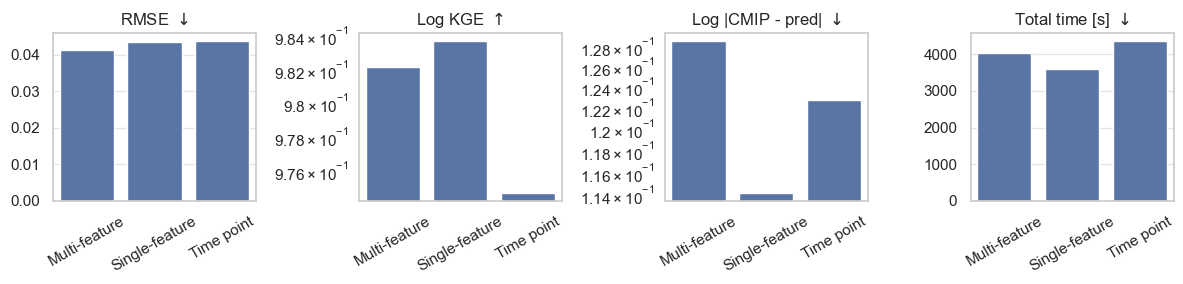

In [8]:
TOKEN_EXPERIMENTS = [
    (11, "Multi-feature"),
    (47, "Time point"),
    (254, "Single-feature"),
]

results_list, pervar_list = [], []
for exp_id, token_type in TOKEN_EXPERIMENTS:
    r, _, _, pv = load_experiments(exp_list=[exp_id], attr_list=["attention_type"], per_var=True)
    r["Token type"] = token_type
    results_list.append(r)
    pervar_list.append(assemble_pervar(pv, exp_id=exp_id, **{"Token type": token_type}))

df_metrics = pd.concat(results_list).sort_values("Token type")
df_metrics["Total time"] = df_metrics["train_time"] + df_metrics["pred_time"]
df_metrics["Total time / epochs"] = df_metrics["Total time"] / df_metrics["stop_epoch"]
df_pervar = pd.concat(pervar_list)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, metric in zip(axes, ["RMSE", "KGE", "CMIP_diff", "Total time"]):
    sns.barplot(data=df_metrics, x="Token type", y=metric, ax=ax)
    if metric == "CMIP_diff":
        ax.set_title(r"Log |CMIP - pred| $\downarrow$")
        ax.set_yscale("log")
    elif metric == "KGE":
        ax.set_title(r"Log KGE $\uparrow$")
        ax.set_yscale("log")
    elif metric == "Total time":
        ax.set_title(r"Total time [s] $\downarrow$")
    else:
        ax.set_title(metric + r" $\downarrow$")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("output/plots/ablation/tokens/token_type.png")
plt.show()


In [9]:
# Generate table for latex
latex = generate_latex_table(df_global=df_metrics, df_pervar=df_pervar, model_col="Token type", bold_best=True)
print(latex)

\begin{table}[htbp]
    \centering
    \caption{Model performance metrics (normalized space)}
    \label{tab:model_performance}
    \resizebox{\textwidth}{!}{%
    \begin{tabular}{lccccccccc}
    \toprule
    Token type & RMSE $\downarrow$ & KGE $\uparrow$ & CMIP MAE $\downarrow$ & \multicolumn{6}{c}{RMSE per parameter $\downarrow$} \\
    \cmidrule(lr){5-10}
     &  &  &  & Potential temperature & Salinity & Oxygen & Nitrate & Silicate & Phosphate \\
    \midrule
    Multi-feature & \textbf{0.0412} & 0.9822 & 0.1286 & 0.0580 & \textbf{0.0261} & 0.0511 & \textbf{0.0096} & 0.0349 & \textbf{0.0123} \\
    Single-feature & 0.0433 & \textbf{0.9837} & \textbf{0.1141} & \textbf{0.0485} & 0.0425 & 0.0566 & 0.0102 & 0.0363 & 0.0144 \\
    Time point & 0.0436 & 0.9747 & 0.1228 & 0.0652 & 0.0398 & \textbf{0.0420} & 0.0099 & \textbf{0.0222} & 0.0134 \\
    \bottomrule
    \end{tabular}
    }
\end{table}


In [10]:
# Times and depths to plot
times = [1772, 2012]
depth = 0.0

# Load data of interest
ablation_dir = Path("D:/phd/output/tuning/mastnet/architecture_ablation/")
model_name = "mastnet"

pred_data = {}
for exp_id, token_type in TOKEN_EXPERIMENTS:
    file_name = ablation_dir / f"exp{exp_id}"
    key = f"{model_name}_exp{exp_id}"

    # Load predictions and true fields, fill true fields with predictions
    df_pred = pd.read_csv(file_name / f"{model_name}_y_pred.csv")
    df_true = pd.read_csv(file_name / f"{model_name}_y_true.csv")
    df_imputed = df_true.fillna(df_pred)

    # Undo scaling
    scalers = joblib.load(file_name / "scalers.joblib")
    for k, v in scalers.items():
        if k in df_pred.columns:
            df_imputed[k] = v.inverse_transform(df_imputed[k].to_numpy().reshape(-1, 1))

    # Drop redundant column
    if "Unnamed: 0" in df_imputed.columns:
        df_imputed = df_imputed.drop("Unnamed: 0", axis=1)

    # Add coordinate info
    df_imputed[config.coordinates] = df[config.coordinates]

    # Filter for depth and time slice
    pred_data[key] = df_imputed[(df_imputed["LEV_M"] == depth) & (df_imputed["DATEANDTIME"].isin(times))]


C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations

C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations

C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using versi

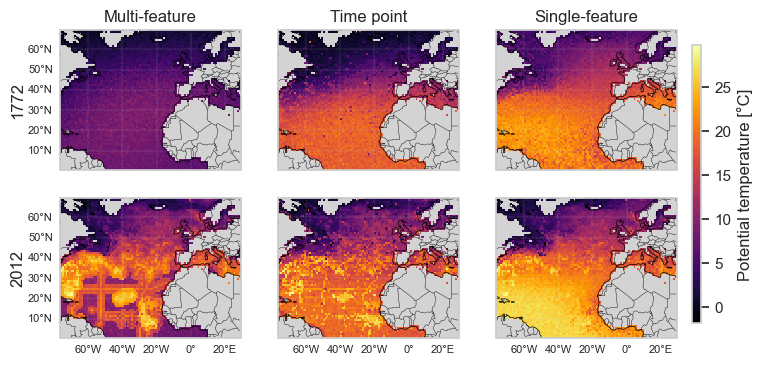

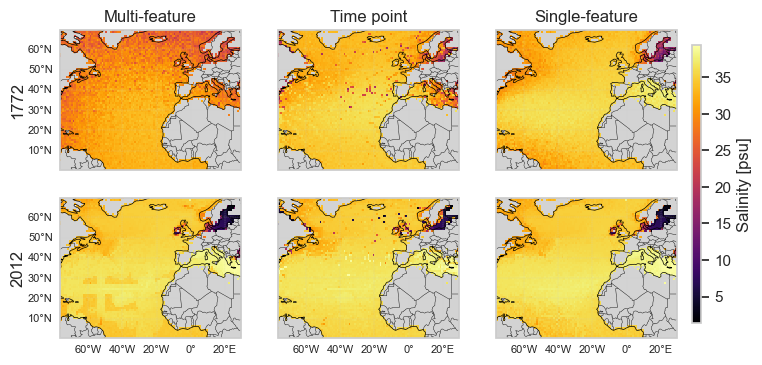

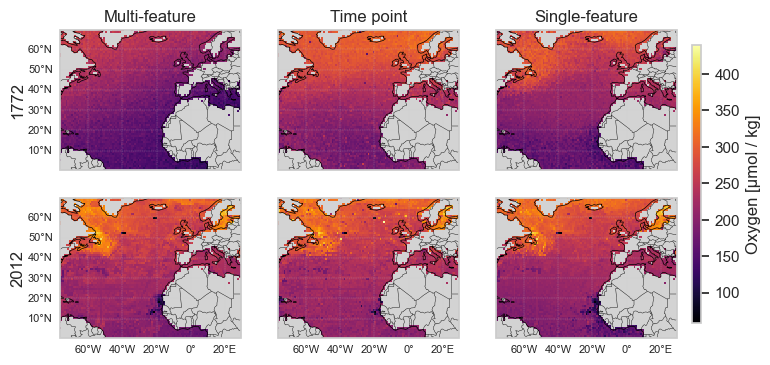

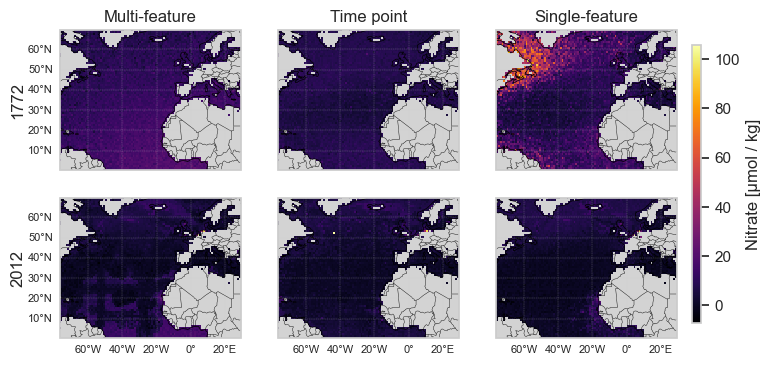

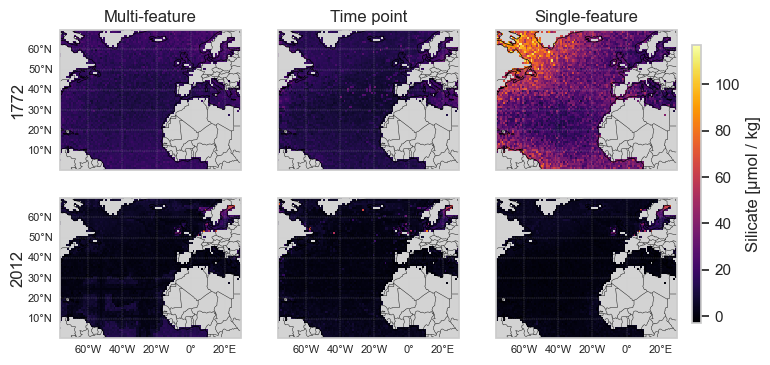

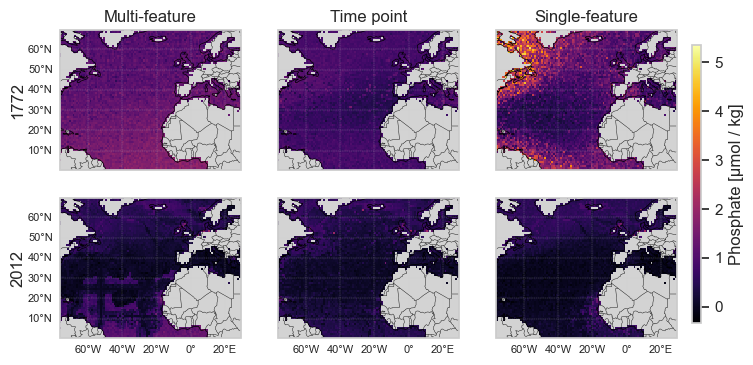

In [11]:
# Plot specified time/depth slices for each parameter
col_items = [(f"mastnet_exp{exp_id}", label) for exp_id, label in TOKEN_EXPERIMENTS]

for parameter in config.parameters:
    gridded = {key: df_to_gridded_da(pred_data[key], value_col=parameter) for key, _ in col_items}
    plot_geo_panels(
        get_data=lambda t, m, _g=gridded: _g[m].sel(time=int(t), depth=0.0),
        row_items=[(t, str(t)) for t in times],
        col_items=col_items,
        plot_config={"cmap": "inferno"},
        colorbar_label=config.parameter_name_unit_map[parameter],
        output_path="output/plots/ablation/tokens",
        filename=f"imputation_depth_maps_token_ablation_{parameter}.png",
        dpi=300,
    )


# Attention type

Ablates the attention mechanism and the optional feature mixer across five attention variant (cross-attention, joint attention, autoencoder, space-time, space-time-depth). The feature mixer is a small MLP applied before or alongside attention; it can operate on features only (`feat`) or features plus mask indicators (`feat_mask`).

## Feature mixer ablation

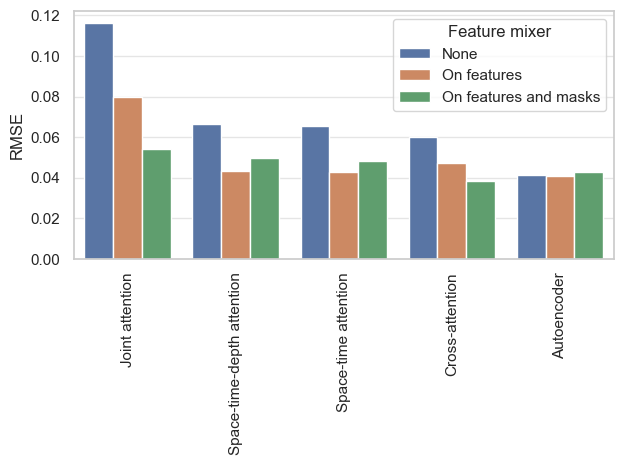

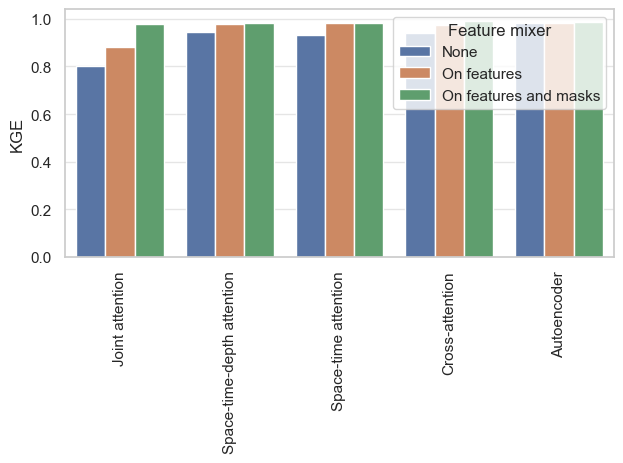

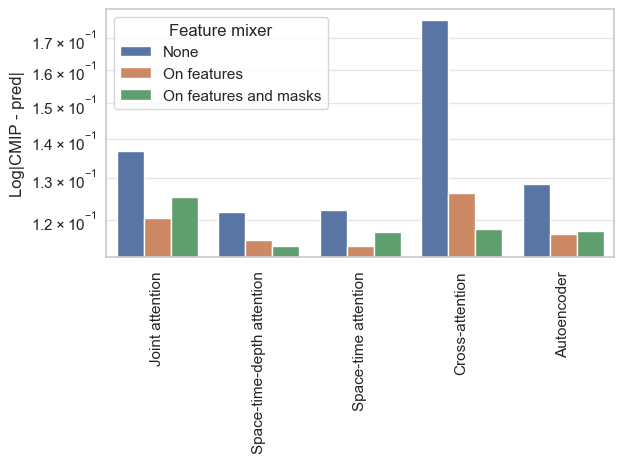

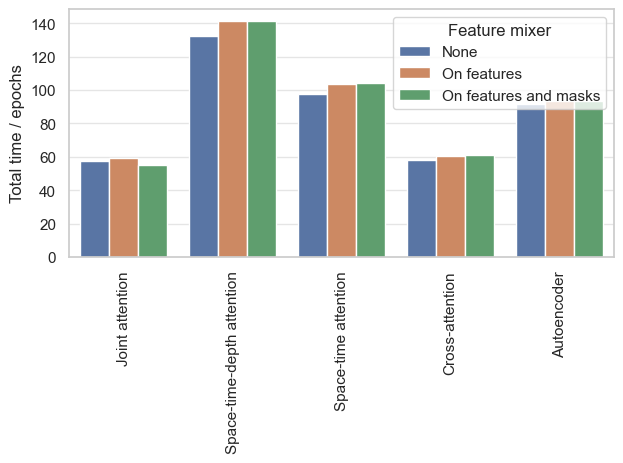

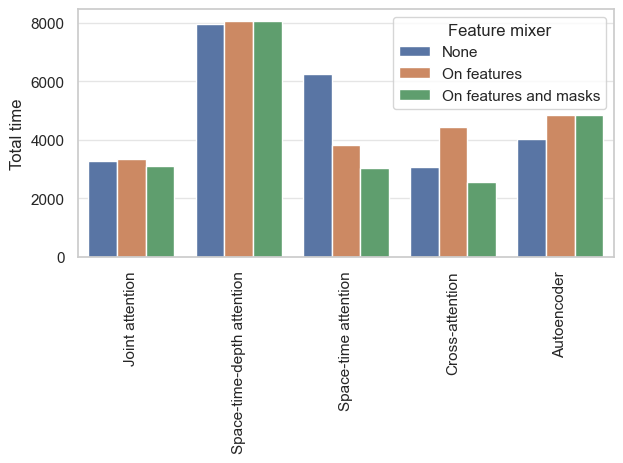

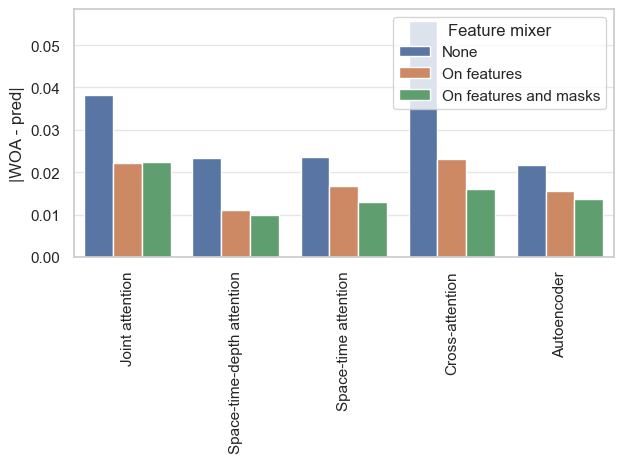

In [8]:
# Feature mixer ablation
exp_ids = [0, 3, 15,  # mha
           10, 250, 251,  # transformer_encoder
           11, 37, 27,  # autoencoder
           17, 31, 72,  # space_time_attention
           18, 248, 249,  # space_time_depth_attention
           ]
attr_list = ["attention_type", "feature_mixer_input", "feature_mixer"]
error_name = "RMSE"

# Load one experiment at a time to collect per-variable metrics for every experiment
results_list, pervar_list = [], []
for exp_id in exp_ids:
    r, _, _, pv = load_experiments(exp_list=[exp_id], attr_list=attr_list, per_var=True)
    results_list.append(r)
    pervar_list.append(assemble_pervar(pv, exp_id=exp_id))

# Assemble results
results = pd.concat(results_list)
df_pervar_attn = pd.concat(pervar_list)

# Define plottable columns
results = results.sort_values(error_name, ascending=False)
results["Feature mixer"] = np.select(
    [~results["feature_mixer"],
     results["feature_mixer"] & (results["feature_mixer_input"] == "feat"),
     results["feature_mixer"] & (results["feature_mixer_input"] == "feat_mask")],
    ["None", "On features", "On features and masks"], default=""
)
results["Total time"] = results["train_time"] + results["pred_time"]
results["Total time epochs"] = results["Total time"] / results["stop_epoch"]

# Barplot per error type
for m in ["RMSE", "KGE", "CMIP_diff", "Total time epochs", "Total time", "WOA_diff"]:
    ax = sns.barplot(data=results, x="attention_type", hue="Feature mixer", y=m)
    plt.xlabel("")
    plt.xticks(rotation=90)
    if m == "CMIP_diff":
        plt.ylabel("Log|CMIP - pred|")
        plt.yscale("log")
        ax.yaxis.grid(True, which="major")
        ax.yaxis.grid(True, which="minor")
    elif m == "WOA_diff":
        plt.ylabel("|WOA - pred|")
    elif m == "Total time epochs":
        plt.ylabel("Total time / epochs")
    else:
        plt.ylabel(m)
    plt.tight_layout()
    plt.savefig(f"output/plots/ablation/attention/feature_mixer_{m}.png")
    plt.show()


In [9]:
results[~results["feature_mixer"]].sort_values("RMSE")


,MAE,RMSE,NRMSE,PCC,R2,KGE,OI,exp_id,train_time,pred_time,stop_epoch,attention_type,feature_mixer_input,feature_mixer,WOA_diff,CMIP_diff,Feature mixer,Total time,Total time epochs
0,0.021046,0.041156,0.123535,0.992971,0.985409,0.982157,0.972752,11,3987.163885,49.561383,44,Autoencoder,feat,False,0.021754,0.128554,None,4036.725268,91.743756
0,0.037637,0.060244,0.186464,0.988183,0.968736,0.938297,0.955162,0,3027.538692,40.315763,53,Cross-attention,feat,False,0.055711,0.176026,None,3067.854455,57.884046
0,0.037643,0.065360,0.200041,0.985329,0.963200,0.930274,0.949913,17,6167.382705,66.261728,64,Space-time attention,feat,False,0.023495,0.122164,None,6233.644434,97.400694
0,0.034719,0.066662,0.202364,0.982936,0.961719,0.945087,0.948542,18,7850.049107,85.728579,60,Space-time-depth attention,feat,False,0.023401,0.121635,None,7935.777685,132.262961
0,0.070045,0.116327,0.350578,0.958254,0.883431,0.799933,0.885320,10,3233.228454,38.334780,57,Joint attention,feat,False,0.038278,0.136804,None,3271.563234,57.395846


In [10]:
# Generate latex results table
results_for_latex = results.copy()
results_for_latex["Attention type"] = results_for_latex["attention_type"]
results_for_latex["Feature mixer"] = np.select(
    [~results["feature_mixer"],
     results["feature_mixer"] & (results["feature_mixer_input"] == "feat"),
     results["feature_mixer"] & (results["feature_mixer_input"] == "feat_mask")],
    ["None", "Features", "Features+masks"], default=""
)
df_pervar_for_latex = df_pervar_attn.merge(
    results_for_latex[["exp_id", "Attention type", "Feature mixer"]], on="exp_id"
)

results_for_latex = results_for_latex.sort_values(["Attention type", "Feature mixer"])
results_for_latex = results_for_latex[results_for_latex["Attention type"] != "Time space attention"]
df_pervar_for_latex = df_pervar_for_latex[df_pervar_for_latex["Attention type"] != "Time space attention"]

latex = generate_latex_table(
    df_global=results_for_latex,
    df_pervar=df_pervar_for_latex,
    model_col="exp_id",
    label_cols=["Attention type", "Feature mixer"],
    bold_best=True,
)
print(latex)


\begin{table}[htbp]
    \centering
    \caption{Model performance metrics (normalised space)}
    \label{tab:model_performance}
    \resizebox{\textwidth}{!}{%
    \begin{tabular}{llccccccccc}
    \toprule
    \multicolumn{2}{l}{Model} & RMSE $\downarrow$ & KGE $\uparrow$ & CMIP MAE $\downarrow$ & \multicolumn{6}{c}{RMSE per parameter $\downarrow$} \\
    \cmidrule(lr){6-11}
    Attention type & Feature mixer &  &  &  & Potential temperature & Salinity & Oxygen & Nitrate & Silicate & Phosphate \\
    \midrule
    Autoencoder & Features & 0.0410 & 0.9817 & 0.1168 & 0.0583 & 0.0255 & \textbf{0.0494} & 0.0109 & 0.0375 & 0.0128 \\
    Autoencoder & Features+masks & 0.0427 & 0.9850 & 0.1174 & 0.0544 & 0.0365 & 0.0535 & 0.0094 & 0.0357 & 0.0125 \\
    Autoencoder & None & 0.0412 & 0.9822 & 0.1286 & 0.0580 & 0.0261 & 0.0511 & 0.0096 & 0.0349 & 0.0123 \\
    Cross-attention & Features & 0.0472 & 0.9727 & 0.1262 & 0.0647 & 0.0304 & 0.0624 & 0.0086 & 0.0359 & 0.0122 \\
    Cross-attention & Feat

## Attention type ablation (no feature mixer)

In [15]:
# Times and depths to plot
depth = 0.0
times = [1772, 2012]

# No feature mixer experiments
ATTENTION_EXPERIMENTS = [
    (0, "Cross-attention"),
    (10, "Joint attention"),
    (11, "Autoencoder"),
    (17, "Space-time attention"),
    (18, "Space-time-depth attention"),
]

ablation_dir = Path("D:/phd/output/tuning/mastnet/architecture_ablation/")
model_name = "mastnet"

pred_data_attn = {}
for exp_id, label in ATTENTION_EXPERIMENTS:
    file_name = ablation_dir / f"exp{exp_id}"
    key = f"{model_name}_exp{exp_id}"

    # Load prediction, true values and generate imputed field
    df_pred = pd.read_csv(file_name / f"{model_name}_y_pred.csv")
    df_true = pd.read_csv(file_name / f"{model_name}_y_true.csv")
    df_imputed = df_true.fillna(df_pred)

    # Unscale imputed values
    scalers = joblib.load(file_name / "scalers.joblib")
    for k, v in scalers.items():
        if k in df_pred.columns:
            df_imputed[k] = v.inverse_transform(df_imputed[k].to_numpy().reshape(-1, 1))

    # Remove redundant column
    if "Unnamed: 0" in df_imputed.columns:
        df_imputed = df_imputed.drop("Unnamed: 0", axis=1)

    # Add coordinate information
    df_imputed[config.coordinates] = df[config.coordinates]

    # Assemble final df and filter for times/depths of interest
    pred_data_attn[key] = df_imputed[(df_imputed["LEV_M"] == depth) & (df_imputed["DATEANDTIME"].isin(times))]


C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations

C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations

C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning:

Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using versi

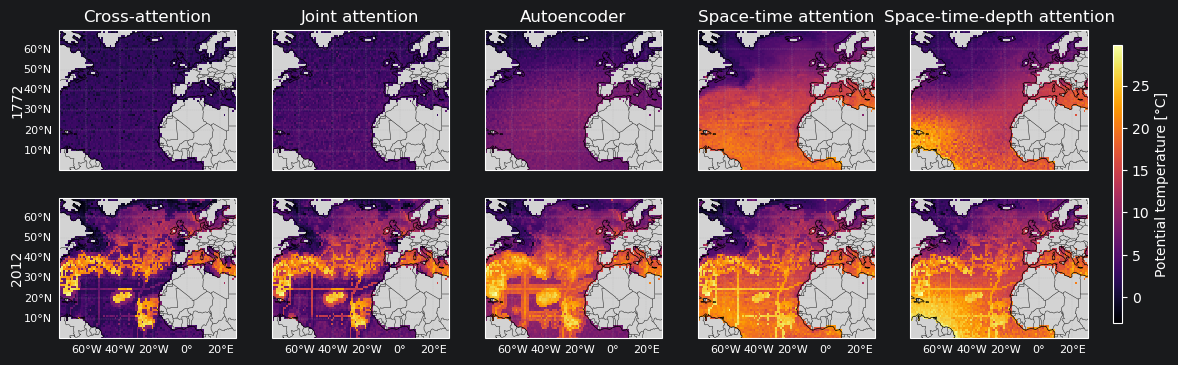

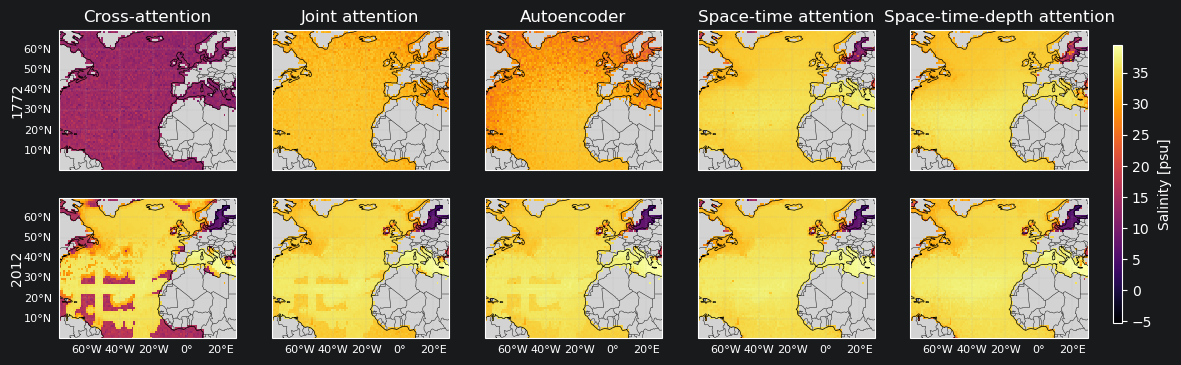

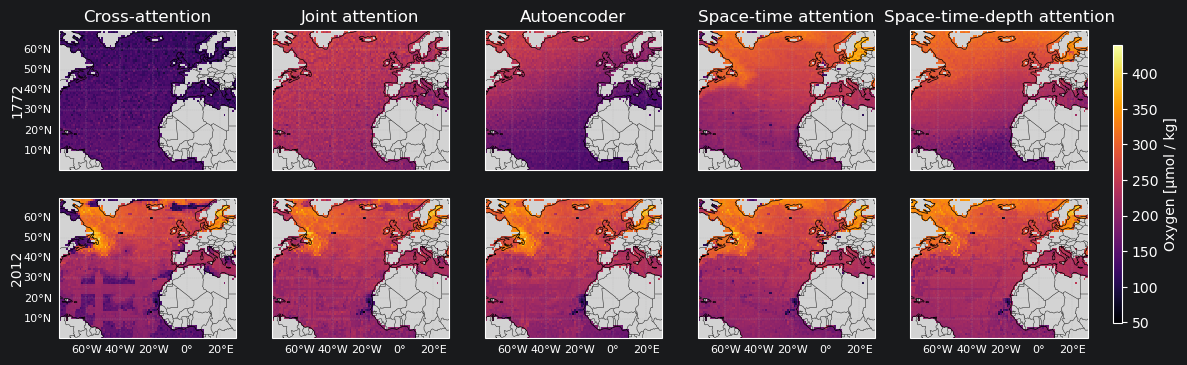

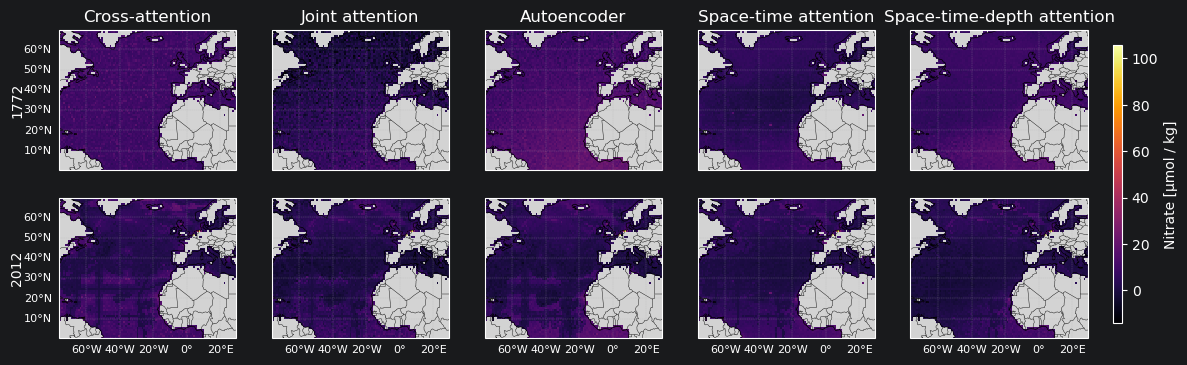

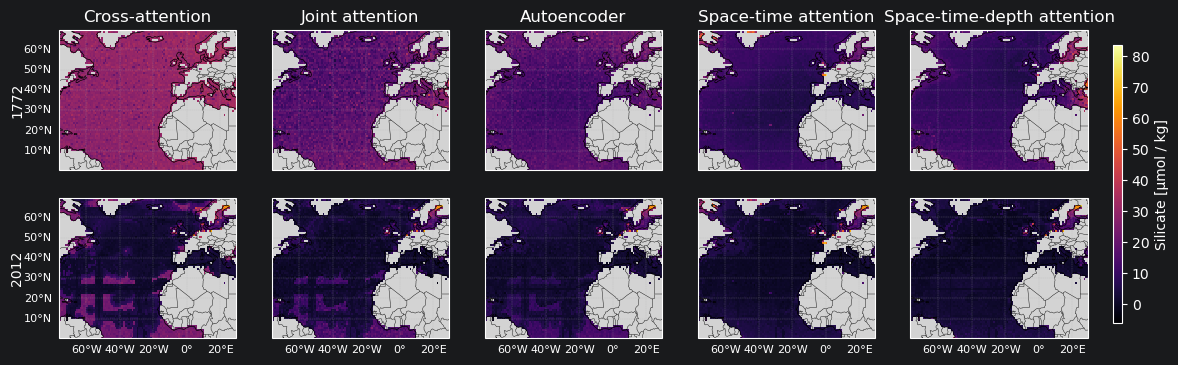

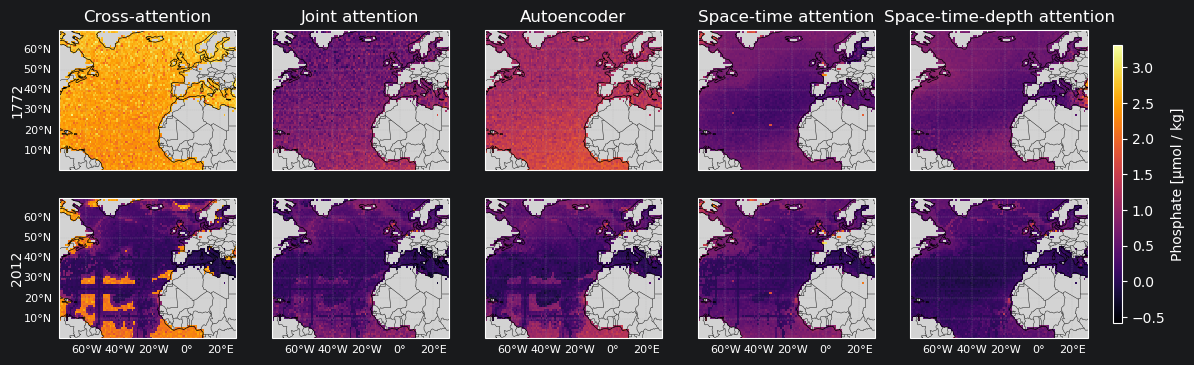

In [16]:
# Plot times/depths slices of interest per parameter
col_items_attn = [(f"mastnet_exp{exp_id}", label) for exp_id, label in ATTENTION_EXPERIMENTS]

for parameter in config.parameters:
    gridded = {key: df_to_gridded_da(pred_data_attn[key], value_col=parameter) for key, _ in col_items_attn}
    plot_geo_panels(
        get_data=lambda t, m, _g=gridded: _g[m].sel(time=int(t), depth=0.0),
        row_items=[(t, str(t)) for t in times],
        col_items=col_items_attn,
        plot_config={"cmap": "inferno"},
        colorbar_label=config.parameter_name_unit_map[parameter],
        output_path="output/plots/ablation/attention",
        filename=f"imputation_depth_maps_attention_ablation_{parameter}.png",
        dpi=300,
    )


In [17]:
# Relative improvement statistics (space-time attention, no feature mixer)
(0.0412 - 0.0410) / 0.0412 * 100

0.4854368932038806

# Masking strategies

Evaluates how the masking strategy *during training* affects generalisation to unseen missing patterns. Three attention types are compared (autoencoder, space-time attention, time-space attention). The effective missingness ratio, i.e. the actual fraction of hidden values is tracked alongside the nominal mask ratio.

In [18]:
exp_map = {
    "autoencoder": {
        "masking": {
            "per_sample": ["exp182", "exp183", "exp184", "exp185", "exp186"],
            "transect": ["exp217", "exp223", "exp229"],
            "transect_random": ["exp218", "exp219", "exp220", "exp221", "exp222", "exp224", "exp225", "exp226",
                                "exp227", "exp228", "exp230", "exp231", "exp232", "exp233", "exp234"],
            "sphere": ["exp187", "exp193", "exp199", "exp205", "exp211"],
            "sphere_random": ["exp188", "exp189", "exp190", "exp191", "exp192",
                              "exp194", "exp195", "exp196", "exp197", "exp198",
                              "exp200", "exp201", "exp202", "exp203", "exp204",
                              "exp206", "exp207", "exp208", "exp209", "exp210",
                              "exp212", "exp213", "exp214", "exp215", "exp216"],
            "combined": ["exp244"],
            "per_feature": ["exp235", "exp236", "exp237", "exp238", "exp239", "exp240", "exp241", "exp242", "exp243"],
        }
    },
    "space_time_attention": {
        "masking": {
            "per_sample": ["exp73", "exp91", "exp92", "exp93", "exp94"],
            "transect": ["exp109", "exp114", "exp174"],
            "transect_random": ["exp139", "exp140", "exp141", "exp142", "exp143", "exp144", "exp145", "exp146",
                                "exp147", "exp148", "exp175", "exp176", "exp177", "exp178", "exp179"],
            "sphere": ["exp104", "exp105", "exp106", "exp107", "exp108"],
            "sphere_random": ["exp149", "exp150", "exp151", "exp152", "exp153",
                              "exp154", "exp155", "exp156", "exp157", "exp158",
                              "exp159", "exp160", "exp161", "exp162", "exp163",
                              "exp164", "exp165", "exp166", "exp167", "exp168",
                              "exp169", "exp170", "exp171", "exp172", "exp173"],
            "combined": ["exp180"],
            "per_feature": ["exp95", "exp96", "exp97", "exp98", "exp99", "exp100", "exp101", "exp102", "exp103"]
        }
    },
}


## Per-sample masking

Randomly hides N $\in$ {1, 2, 3, 4, 5} features per sample (mask ratios 0.3, 0.4, 0.5, 0.7, 0.9). Simulates missing-at-random (MAR) data gaps.

In [19]:
def assemble_df(exp_ids):
    """Compiling relevant information of passed experiment IDs into a df."""
    per_sample = []
    for exp_id in exp_ids:
        masking_dir = ablation_base_dir / exp_id
        df_mask, a, b = load_experiment(dir_path=masking_dir, model_name="mastnet", woa=True, cmip=True)
        df_mask["effective_miss_ratio"] = extract_mean_miss_ratio(exp_id)

        df_mask["sphere_mask_radius"] = ablation_study[exp_id]["config"].sphere_mask_radius
        df_mask["transect_mask_width"] = ablation_study[exp_id]["config"].transect_mask_width
        df_mask["masking_strategies"] = str(ablation_study[exp_id]["config"].masking_strategies)

        per_sample.append(df_mask)

    df_per_sample = pd.concat(per_sample)
    df_per_sample["num_feat"] = df_per_sample["mask_ratio"].map(per_sample_num_map)
    df_per_sample["masking_strategy"] = "Per-sample"

    return df_per_sample


In [20]:
# Plotting functions for different masking errors
def plot_masking_rmse(df_in, save_as=None, dpi=300):
    plt.figure(figsize=(6, 4))
    sns.barplot(df_in, x="num_feat", y="RMSE", hue="Attention type")
    plt.xlabel("Number of randomly hidden features per sample")
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=dpi)
    plt.show()


def plot_masking_kge(df_in, save_as=None, dpi=300):
    plt.figure(figsize=(6, 4))
    sns.barplot(df_in, x="num_feat", y="KGE", hue="Attention type")
    plt.xlabel("Number of randomly hidden features per sample")
    plt.yscale("log")
    plt.ylabel("Log KGE")
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=dpi)
    plt.show()


def plot_masking_woa_diff(df_in, save_as=None, dpi=300):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    temp = df_in.sort_values("num_feat").copy()
    temp["num_feat"] = temp["num_feat"].astype(str)

    sns.barplot(data=temp, x="num_feat", y="WOA_diff", ax=ax1, hue="Attention type")
    ax1.set_yscale("log")
    ax1.set_ylabel("Log |WOA - pred|")

    sns.scatterplot(data=temp, x="num_feat", y="WOA_std", ax=ax2, hue="Attention type", legend=False)
    ax2.set_yscale("log")
    ax2.set_ylabel("Log std")
    ax2.set_xlabel("Number of randomly hidden features per sample")
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=dpi)
    plt.show()


def plot_masking_cmip_diff(df_in, save_as=None, dpi=300):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    temp = df_in.sort_values("num_feat").copy()
    temp["num_feat"] = temp["num_feat"].astype(str)

    sns.barplot(data=temp, x="num_feat", y="CMIP_diff", ax=ax1, hue="Attention type")
    ax1.set_yscale("log")
    ax1.set_ylabel("Log |CMIP - pred|")

    sns.scatterplot(data=temp, x="num_feat", y="CMIP_std", ax=ax2, hue="Attention type", legend=False)
    ax2.set_yscale("log")
    ax2.set_ylabel("Log std")
    ax2.set_xlabel("Number of randomly hidden features per sample")
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=dpi)
    plt.show()


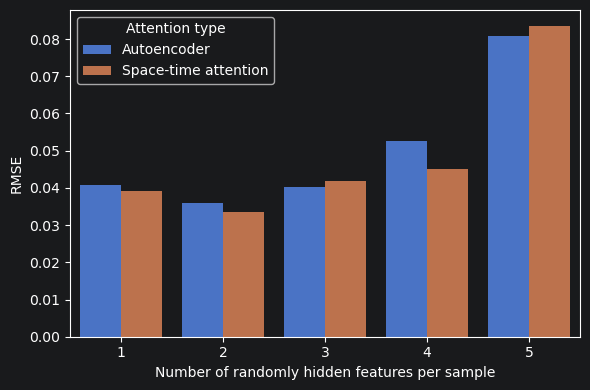

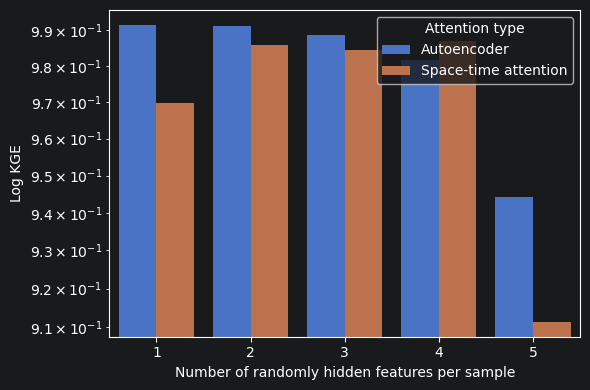

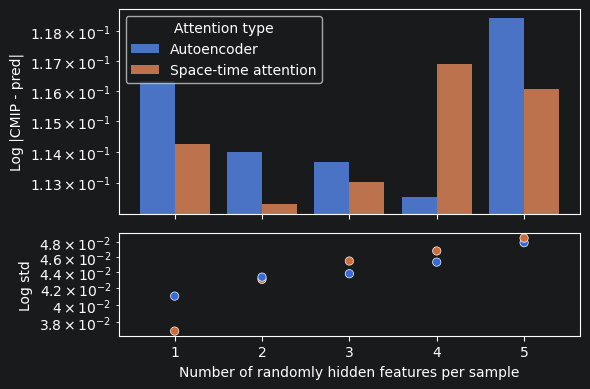

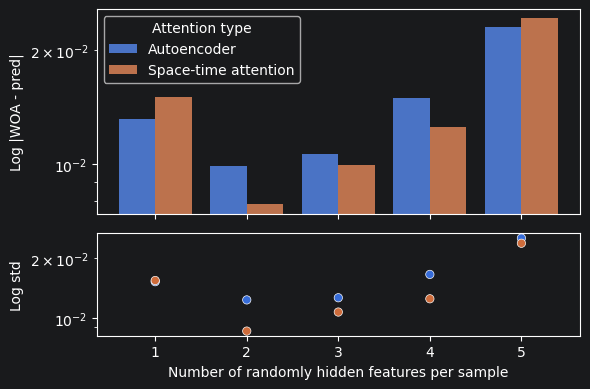

In [21]:
# Get info for each attention model
df_per_sample = []
for model_name, exp_dict in exp_map.items():
    exp_ids = exp_dict["masking"]["per_sample"]
    temp = assemble_df(exp_ids)
    temp["Attention type"] = attention_name_map[model_name]
    df_per_sample.append(temp)
df_per_sample = pd.concat(df_per_sample)

# Error plots
plot_masking_rmse(df_per_sample), save_as="output/plots/ablation/masking/masking_rmse.png", dpi=300)
plot_masking_kge(df_per_sample, save_as="output/plots/ablation/masking/masking_kge.png", dpi=300)
plot_masking_cmip_diff(df_per_sample, save_as="output/plots/ablation/masking/masking_cmip_diff.png", dpi=300)
plot_masking_woa_diff(df_per_sample, save_as="output/plots/ablation/masking/masking_woa_diff.png", dpi=300)


## Transect masking

Masks all features along a vertical or horizontal transect of fixed width. Simulates ship-track or mooring-line gaps `transect_mask_width` controls the transect footprint; orientation 0=axis-aligned, 1=rotated.

In [22]:
def assemble_transect_df(exp_ids_transect, exp_ids_transect_random):
    """Compiling relevant information of passed experiment IDs into a df."""
    transect = []
    for exp_id in exp_ids_transect + exp_ids_transect_random:
        masking_dir = ablation_base_dir / exp_id
        df_mask, a, b = load_experiment(dir_path=masking_dir, model_name="mastnet", woa=True, cmip=True)
        df_mask["effective_miss_ratio"] = extract_mean_miss_ratio(exp_id)

        if exp_id in exp_ids_transect:
            df_mask["num_feat"] = 0

        transect_width = ablation_study[exp_id]["config"].transect_mask_width
        df_mask["transect_mask_width"] = transect_width
        df_mask["sphere_mask_radius"] = ablation_study[exp_id]["config"].sphere_mask_radius
        df_mask["masking_strategies"] = str(ablation_study[exp_id]["config"].masking_strategies)
        df_mask["masking_strategy"] = (
            f"Transect (w={transect_width})" if df_mask["transect_mask_orientation"].values[0] == 0
            else f"Transect (w={transect_width}, aligned)"
        )

        transect.append(df_mask)

    df_transect = pd.concat(transect)
    df_transect["num_feat"] = df_transect["mask_ratio"].map(per_sample_num_map)
    df_transect.loc[df_transect["exp_id"].isin(exp_ids_transect), "num_feat"] = 0

    return df_transect


In [23]:
# Get transect masking results
df_transect = []
for model_name, exp_dict in exp_map.items():
    exp_ids_transect = exp_dict["masking"]["transect"]
    exp_ids_transect_random = exp_dict["masking"]["transect_random"]
    temp = assemble_transect_df(exp_ids_transect, exp_ids_transect_random)
    temp["Attention type"] = attention_name_map[model_name]
    df_transect.append(temp)
df_transect = pd.concat(df_transect)


## Spherical masking

Masks all features within a spatial cylinder of radius `sphere_mask_radius` (degrees). Simulates regional data gaps such as under-sampled ocean basins.

In [24]:
def assemble_sphere_df(exp_ids_sphere, exp_ids_sphere_random):
    """Compiling relevant information of passed experiment IDs into a df."""
    sphere = []
    for exp_id in exp_ids_sphere + exp_ids_sphere_random:
        masking_dir = ablation_base_dir / exp_id
        df_mask, a, b = load_experiment(dir_path=masking_dir, model_name="mastnet", woa=True, cmip=True)
        df_mask["effective_miss_ratio"] = extract_mean_miss_ratio(exp_id)

        df_mask["transect_mask_width"] = ablation_study[exp_id]["config"].transect_mask_width
        df_mask["sphere_mask_radius"] = ablation_study[exp_id]["config"].sphere_mask_radius
        df_mask["masking_strategies"] = str(ablation_study[exp_id]["config"].masking_strategies)
        df_mask["masking_strategy"] = "Cylinder (r=" + str(df_mask["sphere_mask_radius"].values[0]) + ")"
        sphere.append(df_mask)

    df_spherical = pd.concat(sphere)
    df_spherical["num_feat"] = df_spherical["mask_ratio"].map(per_sample_num_map)
    df_spherical.loc[df_spherical["exp_id"].isin(exp_ids_sphere), "num_feat"] = 0

    return df_spherical


In [25]:
# Get cylindrical masking results
df_sphere = []
for model_name, exp_dict in exp_map.items():
    exp_ids_sphere = exp_dict["masking"]["sphere"]
    exp_ids_sphere_random = exp_dict["masking"]["sphere_random"]
    temp = assemble_sphere_df(exp_ids_sphere, exp_ids_sphere_random)
    temp["Attention type"] = attention_name_map[model_name]
    df_sphere.append(temp)
df_sphere = pd.concat(df_sphere)


## Combined

Applies a mix of per-sample, transect, and spherical masking within a single training run to expose the model to all gap geometries simultaneously.

In [26]:
def assemble_combined_df(exp_ids):
    """Compiling relevant information of passed experiment IDs into a df."""
    combined = []
    for exp_id in exp_ids:
        masking_dir = ablation_base_dir / exp_id
        df_mask, a, b = load_experiment(dir_path=masking_dir, model_name="mastnet", woa=True, cmip=True)
        df_mask["effective_miss_ratio"] = extract_mean_miss_ratio(exp_id)

        if exp_id in ["exp244"]:
            df_mask["num_feat"] = 1

        df_mask["transect_mask_width"] = ablation_study[exp_id]["config"].transect_mask_width
        df_mask["sphere_mask_radius"] = ablation_study[exp_id]["config"].sphere_mask_radius
        df_mask["masking_strategies"] = str(ablation_study[exp_id]["config"].masking_strategies)
        df_mask["masking_strategy"] = "Combined"
        combined.append(df_mask)

    df_combined = pd.concat(combined)
    df_combined["num_feat"] = df_combined["mask_ratio"].map(per_sample_num_map)
    df_combined.loc[df_combined["exp_id"].isin(exp_ids), "num_feat"] = 1

    return df_combined


def plot_masking_heatmap(df, error_name="RMSE", underline=[], save_as=None, dpi=150):
    """Plot heatmap for various masking strategies with varying parameters."""
    # Masking strategy order
    strategies = sorted(df["masking_strategy"].unique())
    strategies = ["Per-sample"] + [s for s in strategies if s not in ["Per-sample", "Combined"]] + ["Combined"]

    # Pivot for RMSE
    error_pivot = df.pivot_table(
        index="masking_strategy",
        columns="num_feat",
        values=error_name,
        aggfunc="mean"
    ).reindex(strategies)

    # Pivot effective miss ratio
    miss_pivot = None
    if "effective_miss_ratio" in df.columns and df["effective_miss_ratio"].notna().any():
        miss_pivot = df.pivot_table(
            index="masking_strategy",
            columns="num_feat",
            values="effective_miss_ratio",
            aggfunc="mean"
        ).reindex(strategies)

    # Pivot exp_id
    expid_pivot = df.pivot_table(
        index="masking_strategy",
        columns="num_feat",
        values="exp_id",
        aggfunc="first"
    ).reindex(strategies)

    # Plot
    fig, axes = plt.subplots(1, 2 if miss_pivot is not None else 1, figsize=(14, 5))
    ax1, ax2 = axes

    # Error heatmap
    sns.heatmap(error_pivot, annot=False, fmt=".3f", cmap="magma", ax=ax1)
    ax1.set_title(f"{error_name}")
    ax1.set_xlabel("Num. features masked")
    ax1.set_ylabel("Masking strategy")

    # Custom annotations (underlining)
    # Normalisation used by heatmap
    norm = mcolors.Normalize(vmin=np.nanmin(error_pivot.values), vmax=np.nanmax(error_pivot.values))
    cmap = plt.get_cmap("magma")
    for y in range(error_pivot.shape[0]):
        for x in range(error_pivot.shape[1]):
            val = error_pivot.iloc[y, x]
            exp_id = expid_pivot.iloc[y, x]

            if pd.isna(val):
                continue

            # Get actual cell color
            rgba = cmap(norm(val))

            # Perceived luminance as threshold for text colour
            luminance = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
            text_color = "black" if luminance > 0.6 else "white"
            text = f"{val:.3f}"

            # Draw text
            ax1.text(x + 0.5, y + 0.5, text, ha="center", va="center", color=text_color)

            # Underline selected experiments
            if exp_id in underline:
                y_line = y + 0.68
                ax1.plot([x + 0.28, x + 0.72], [y_line, y_line], color=text_color, linewidth=1.5)

    # Effective miss ratio heatmap
    sns.heatmap(miss_pivot, annot=True, fmt=".4f", cmap="magma", ax=ax2)
    ax2.set_title("Effective Mask Ratio")
    ax2.set_xlabel("Num. features masked")
    ax2.set_ylabel("")

    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=dpi)
    plt.show()

In [27]:
# Get results for combined masking
df_combined = []
for model_name, exp_dict in exp_map.items():
    exp_ids_combined = exp_dict["masking"]["combined"]
    temp = assemble_combined_df(exp_ids_combined)
    temp["Attention type"] = attention_name_map[model_name]
    df_combined.append(temp)
df_combined = pd.concat(df_combined)

## Heatmaps

Summarises RMSE, CMIP diff, and WOA diff by masking strategy and number of hidden features. Experiments listed in `exp_ids_with_transect_artifacts_in_potT` have known potential-temperature artifacts from transect masking and are underlined for awareness.

Autoencoder


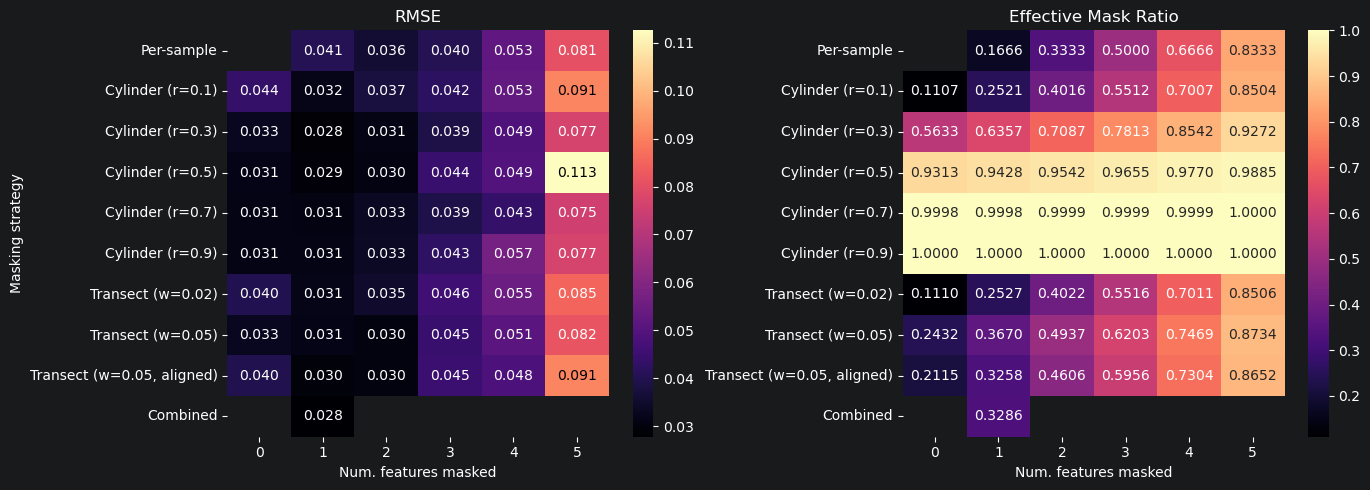

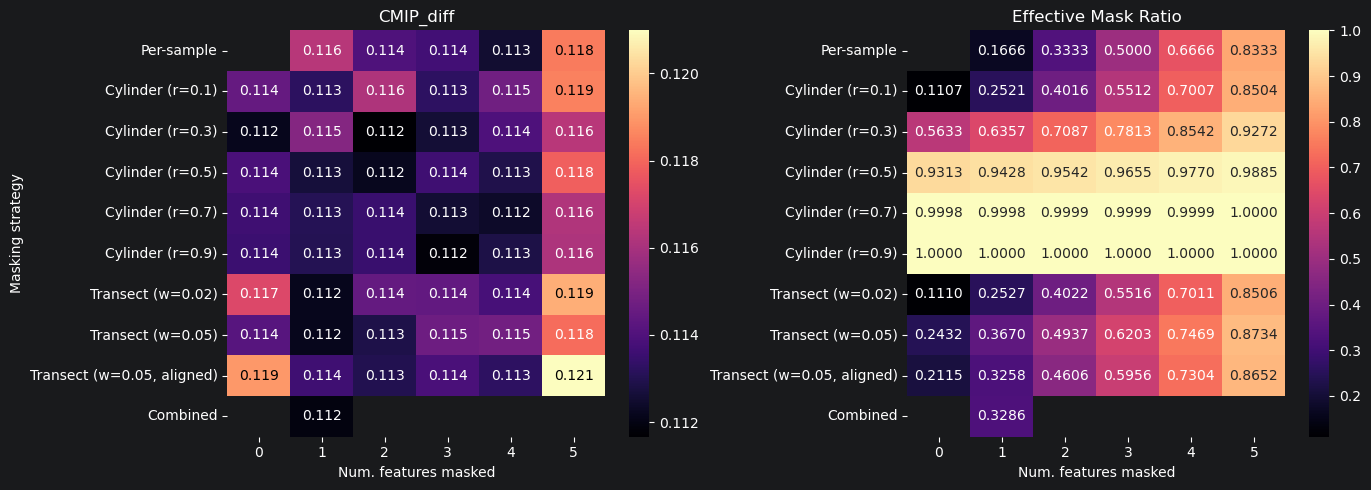

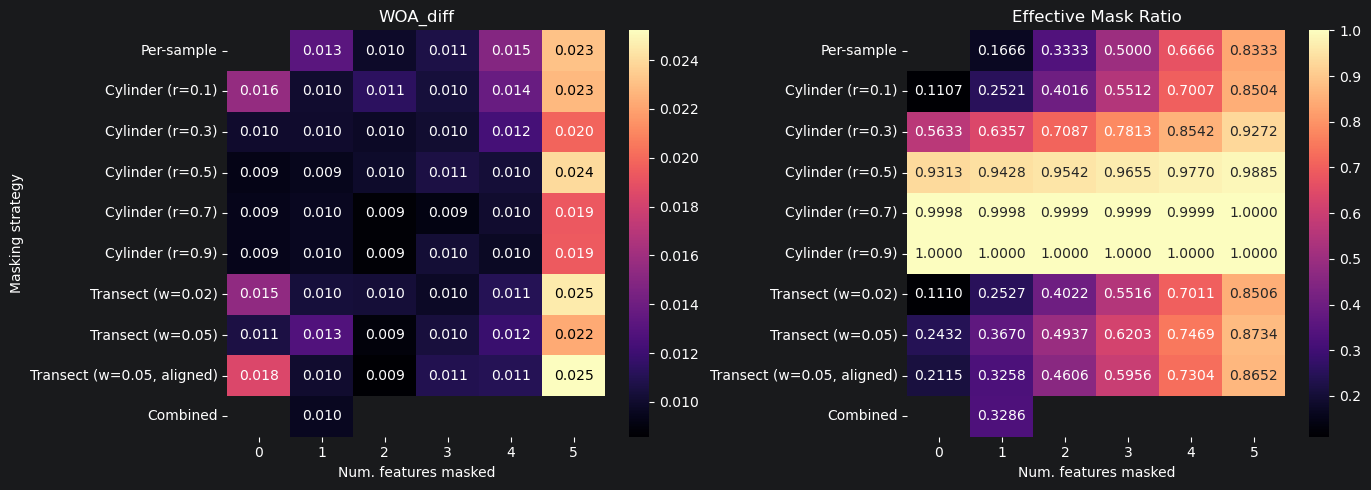

Space-time attention


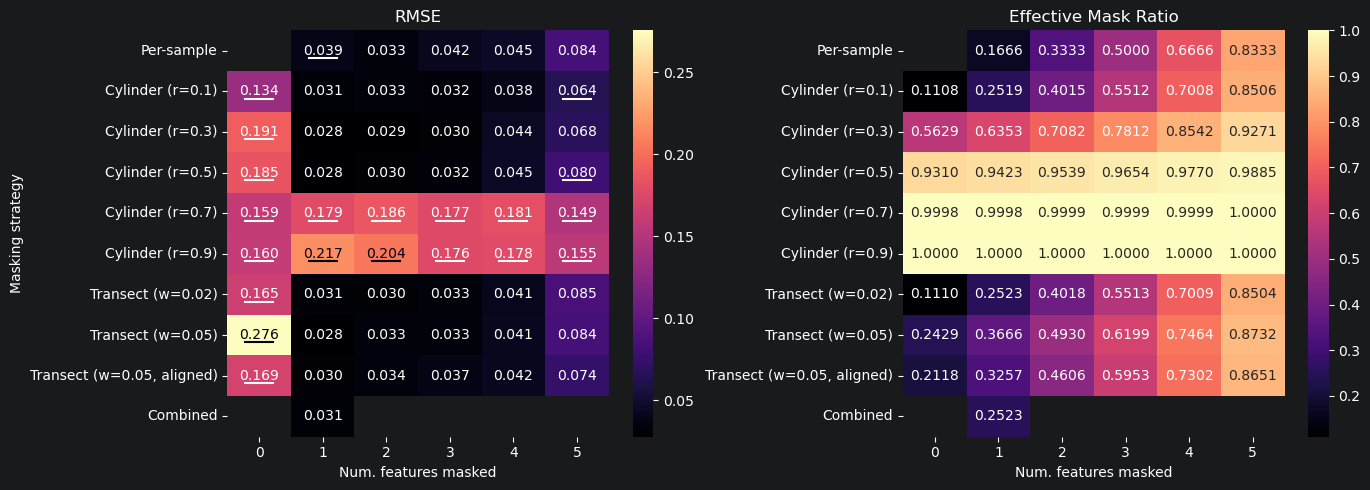

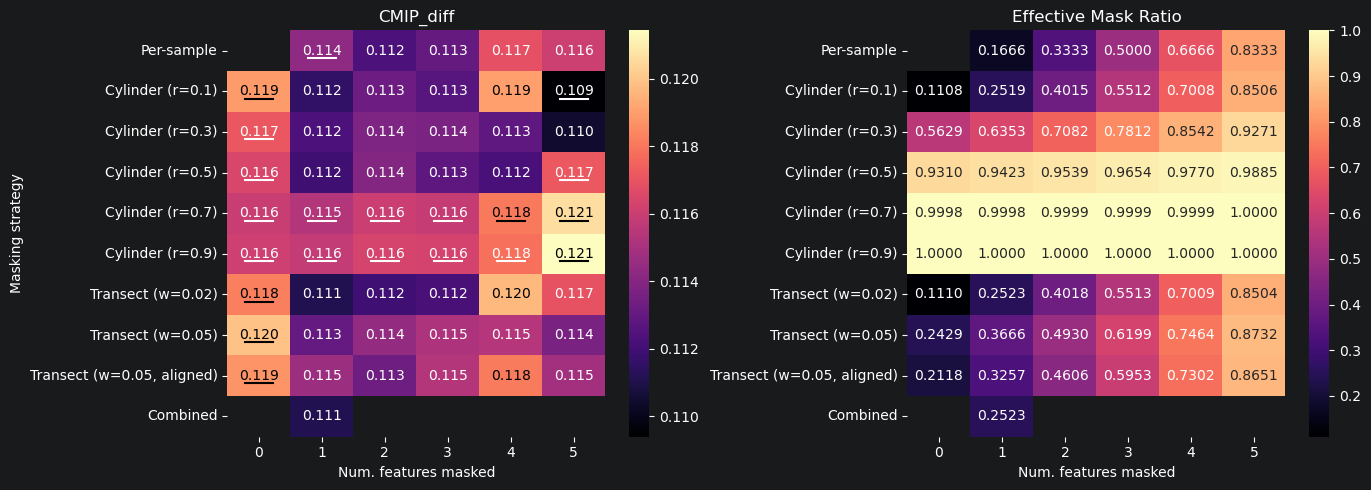

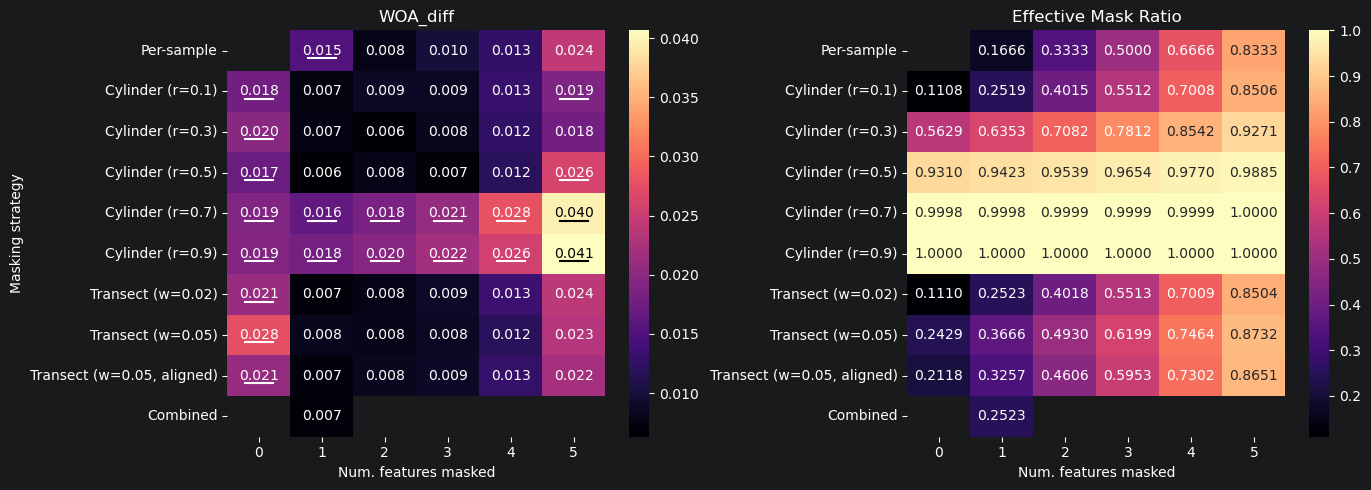

In [28]:
df_all = pd.concat([df_per_sample, df_transect, df_sphere, df_combined], ignore_index=True)

# Experiments with known potential-temperature artifacts from transect masking
exp_ids_with_transect_artifacts_in_potT = (
        ["exp73", "exp109", "exp114", "exp174", "exp104", "exp105", "exp106", "exp107", "exp108",
         "exp152", "exp153", "exp157", "exp158", "exp162", "exp163", "exp167", "exp168",
         "exp169", "exp171", "exp172", "exp173"] +
        ["exp261", "exp266", "exp267", "exp272", "exp277", "exp278", "exp279", "exp280", "exp281",
         "exp282", "exp283", "exp284", "exp285", "exp286", "exp287", "exp288", "exp289", "exp290",
         "exp291", "exp296", "exp297", "exp302", "exp303", "exp317"]
)

# Heatmap plot per model and error type
for model_name, exp_dict in exp_map.items():
    attn_label = attention_name_map[model_name]
    print(attn_label)
    for error_name in ["RMSE", "CMIP_diff", "WOA_diff"]:
        temp = df_all[df_all["Attention type"] == attn_label]
        plot_masking_heatmap(
            temp, error_name=error_name,
            underline=exp_ids_with_transect_artifacts_in_potT,
            #save_as=f"output/plots/ablation/masking/masking_heatmap_{attn_label}_{error_name}.png"
        )


In [29]:
# Error correlations
for attn_label in df_all["Attention type"].unique():
    print(attn_label)
    temp = df_all[df_all["Attention type"] == attn_label]
    temp_corr = temp[["RMSE", "WOA_diff", "CMIP_diff", "effective_miss_ratio"]].corr()
    print(temp_corr)
    print()


Autoencoder
                          RMSE  WOA_diff  CMIP_diff  effective_miss_ratio
RMSE                  1.000000  0.897572   0.738506              0.351530
WOA_diff              0.897572  1.000000   0.871255              0.117499
CMIP_diff             0.738506  0.871255   1.000000             -0.016562
effective_miss_ratio  0.351530  0.117499  -0.016562              1.000000

Space-time attention
                          RMSE  WOA_diff  CMIP_diff  effective_miss_ratio
RMSE                  1.000000  0.716098   0.608750              0.286892
WOA_diff              0.716098  1.000000   0.688786              0.396748
CMIP_diff             0.608750  0.688786   1.000000              0.144072
effective_miss_ratio  0.286892  0.396748   0.144072              1.000000



## Per-feature masking

Masks a fixed fraction of all samples per feature.

In [30]:
def assemble_per_feature_df(exp_ids):
    """Compiling relevant information of passed experiment IDs into a df."""
    per_feature = []
    for exp_id in exp_ids:
        masking_dir = ablation_base_dir / exp_id
        df_mask, a, b = load_experiment(dir_path=masking_dir, model_name="mastnet", woa=True, cmip=True)
        df_mask["effective_miss_ratio"] = extract_mean_miss_ratio(exp_id)
        per_feature.append(df_mask)
    return pd.concat(per_feature)


def plot_masking_per_feature_error(df_in, x="mask_ratio", y="RMSE", y_label=None,
                                   y_scale=None, save_as=None, dpi=300):
    """Error plot for per-feature masking."""
    plt.figure(figsize=(6, 4))
    sns.barplot(df_in, x=x, y=y, hue="Attention type")
    plt.xlabel("Mask ratio")
    if y_label:
        plt.ylabel(y_label)
    if y_scale:
        plt.yscale(y_scale)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=dpi)
    plt.show()


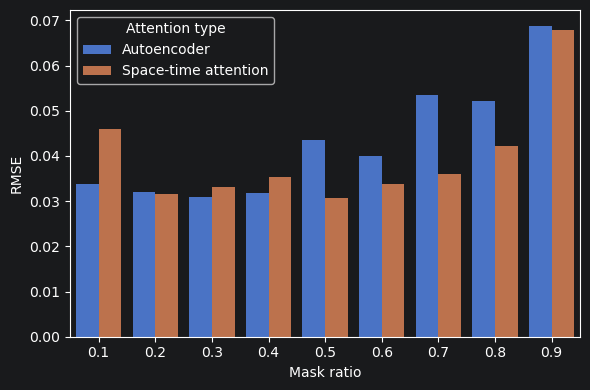

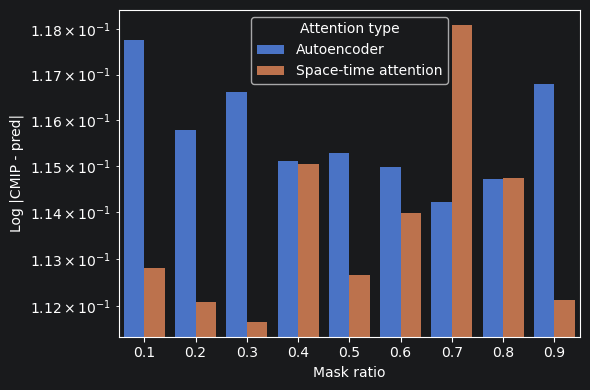

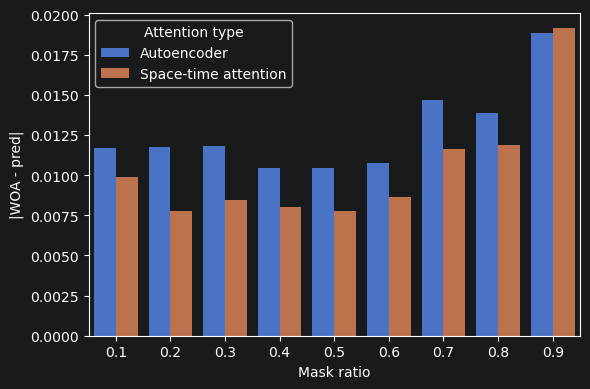

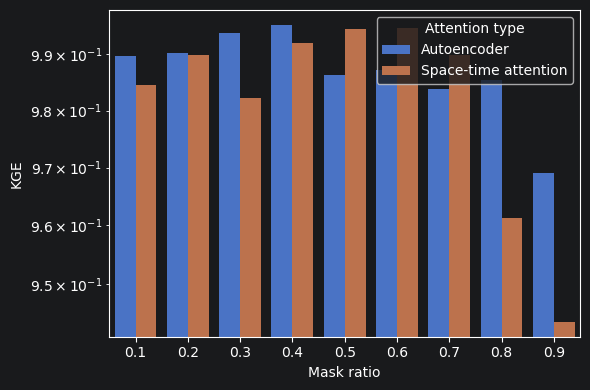

In [31]:
# Get results for per-feature masking
df_per_feature = []
for model_name, exp_dict in exp_map.items():
    exp_ids = exp_dict["masking"]["per_feature"]
    temp = assemble_per_feature_df(exp_ids)
    temp["Attention type"] = attention_name_map[model_name]
    df_per_feature.append(temp)
df_per_feature = pd.concat(df_per_feature)

# Plotting
plot_masking_per_feature_error(df_per_feature, x="mask_ratio", y="RMSE",
                               save_as="output/plots/ablation/masking/masking_per_feature_rmse.png", dpi=300)
plot_masking_per_feature_error(df_per_feature, x="mask_ratio", y="CMIP_diff",
                               y_label="Log |CMIP - pred|", y_scale="log",
                               save_as="output/plots/ablation/masking/masking_per_feature_CMIP_diff.png", dpi=300)
plot_masking_per_feature_error(df_per_feature, x="mask_ratio", y="WOA_diff",
                               y_label="|WOA - pred|",
                               save_as="output/plots/ablation/masking/masking_per_feature_WOA_diff.png", dpi=300)
plot_masking_per_feature_error(df_per_feature, x="mask_ratio", y="KGE",
                               y_label="KGE", y_scale="log",
                               save_as="output/plots/ablation/masking/masking_per_feature_KGE.png", dpi=300)


In [32]:
# Error correlations
for attn_label in df_per_feature["Attention type"].unique():
    print(attn_label)
    temp = df_per_feature[df_per_feature["Attention type"] == attn_label]
    temp_corr = temp[["RMSE", "WOA_diff", "CMIP_diff", "effective_miss_ratio"]].corr()
    print(temp_corr)
    print()


Autoencoder
                          RMSE  WOA_diff  CMIP_diff  effective_miss_ratio
RMSE                  1.000000  0.882025  -0.157065              0.892935
WOA_diff              0.882025  1.000000   0.141738              0.681617
CMIP_diff            -0.157065  0.141738   1.000000             -0.477059
effective_miss_ratio  0.892935  0.681617  -0.477059              1.000000

Space-time attention
                          RMSE  WOA_diff  CMIP_diff  effective_miss_ratio
RMSE                  1.000000  0.937387  -0.180991              0.482974
WOA_diff              0.937387  1.000000   0.016616              0.705530
CMIP_diff            -0.180991  0.016616   1.000000              0.377931
effective_miss_ratio  0.482974  0.705530   0.377931              1.000000



In [33]:
df_per_feature.sort_values("RMSE")


,MAE,RMSE,NRMSE,PCC,R2,KGE,OI,exp_id,mask_ratio,transect_mask_orientation,sphere_mask_radius,masking_strategies,transect_mask_width,WOA_diff,WOA_std,CMIP_diff,CMIP_std,effective_miss_ratio,Attention type
0,0.015251,0.030667,0.090465,0.995944,0.991898,0.994512,0.981082,exp99,0.5,0.0,0.1,['per_feature'],0.05,0.007782,0.009144,0.112660,0.043465,0.499846,Space-time attention
0,0.014733,0.030850,0.090750,0.995898,0.991802,0.993670,0.980945,exp237,0.3,0.0,0.1,['per_feature'],0.05,0.011846,0.015775,0.116614,0.043700,0.296899,Autoencoder
0,0.016236,0.031552,0.093117,0.995769,0.991424,0.989794,0.980416,exp96,0.2,0.0,0.1,['per_feature'],0.05,0.007749,0.008724,0.112082,0.042609,0.195278,Space-time attention
0,0.015905,0.031809,0.093624,0.995636,0.991284,0.995195,0.980221,exp238,0.4,0.0,0.1,['per_feature'],0.05,0.010427,0.012392,0.115118,0.045864,0.398364,Autoencoder
0,0.014952,0.032124,0.095076,0.995553,0.991110,0.990116,0.979981,exp236,0.2,0.0,0.1,['per_feature'],0.05,0.011730,0.015091,0.115787,0.045210,0.195166,Autoencoder
0,0.017318,0.033163,0.097647,0.995411,0.990526,0.982267,0.979186,exp97,0.3,0.0,0.1,['per_feature'],0.05,0.008475,0.008904,0.111673,0.042702,0.296793,Space-time attention
0,0.016527,0.033679,0.099134,0.995105,0.990229,0.994630,0.978787,exp100,0.6,0.0,0.1,['per_feature'],0.05,0.008661,0.009685,0.113981,0.042971,0.593746,Space-time attention
0,0.016473,0.033737,0.100065,0.995103,0.990195,0.989572,0.978742,exp235,0.1,0.0,0.1,['per_feature'],0.05,0.011703,0.014997,0.117761,0.047204,0.093706,Autoencoder
0,0.017357,0.035377,0.104067,0.994623,0.989219,0.991977,0.977459,exp98,0.4,0.0,0.1,['per_feature'],0.05,0.007996,0.009231,0.115045,0.043500,0.398328,Space-time attention
0,0.020319,0.036097,0.105588,0.994461,0.988775,0.989816,0.976888,exp101,0.7,0.0,0.1,['per_feature'],0.05,0.011648,0.011844,0.118100,0.047070,0.695268,Space-time attention


In [34]:
df_all.to_csv("masking_ablation.csv", index=False)


In [35]:
# Latex table
t = df_per_feature[df_per_feature["Attention type"] == "Space-time attention"]
t = t.rename(columns={"mask_ratio": "Mask ratio", "effective_miss_ratio": "Effective missingness [%]"})
t["Effective missingness [%]"] = round((t["Effective missingness [%]"] * 100))
t[["Mask ratio", "RMSE", "KGE"]].round(4).to_latex()


'\\begin{tabular}{lrrr}\n\\toprule\n & Mask ratio & RMSE & KGE \\\\\n\\midrule\n0 & 0.100000 & 0.045900 & 0.984500 \\\\\n0 & 0.200000 & 0.031600 & 0.989800 \\\\\n0 & 0.300000 & 0.033200 & 0.982300 \\\\\n0 & 0.400000 & 0.035400 & 0.992000 \\\\\n0 & 0.500000 & 0.030700 & 0.994500 \\\\\n0 & 0.600000 & 0.033700 & 0.994600 \\\\\n0 & 0.700000 & 0.036100 & 0.989800 \\\\\n0 & 0.800000 & 0.042100 & 0.961300 \\\\\n0 & 0.900000 & 0.067900 & 0.943500 \\\\\n\\bottomrule\n\\end{tabular}\n'

In [36]:
# Relative improvement from per-feature masking
(0.276 - 0.028) / 0.276 * 100


89.85507246376811

# Overview: all experiments

Flat directory scan loads global and per-variable metrics for all architecture ablation experiments (+300 experiments), then ranks them. Masking-strategy experiments are excluded from the ranking since they vary training distribution rather than architecture.

In [11]:
model_name = "mastnet"

# Load metrics by scanning ablation directories
global_rows = []
pervar_rows = []
base_path = Path(config.output_dir_tuning) / model_name / "architecture_ablation"
base_path2 = Path("D:/phd/output/tuning/mastnet/architecture_ablation/")

seen = set()  # deduplicate paths that exist in both base dirs()
for out_dir in glob(str(base_path / "*")) + glob(str(base_path2 / "*")):
    out_dir = Path(out_dir)
    if out_dir.name in seen:
        continue
    seen.add(out_dir.name)

    exp_id = out_dir.name
    file_path = out_dir / f"model{model_name}_splitfinal_trial0.json"

    if not file_path.exists():
        continue

    res = json.load(open(file_path, "r"))

    global_rows.append({
        "exp_id": exp_id,
        "attention_type": res["hyps"]["model"]["cfg"].get("attention_type", ""),
        **res["test_metrics"]["Global"]
    })

    for param, metrics in res["test_metrics"]["PerVariable"].items():
        pervar_rows.append({
            "exp_id": exp_id,
            "parameter": param,
            **metrics
        })

df_global = pd.DataFrame(global_rows)
df_pervar = pd.DataFrame(pervar_rows)
df_pervar_long = df_pervar.melt(id_vars=["exp_id", "parameter"], var_name="metric", value_name="value")


In [12]:
# Exclude masking experiments
df_global = df_global[~df_global.exp_id.isin(masking_exp_ids)]
df_pervar = df_pervar[~df_pervar.exp_id.isin(masking_exp_ids)]


In [13]:
# Global ranking across all metrics
df = df_global.copy()

ranked = pd.DataFrame()
ranked["exp_id"] = df["exp_id"]

for min_metric in ["MAE", "RMSE"]:
    if min_metric in df.columns:
        ranked[min_metric] = df[min_metric].rank(ascending=True)

for max_metric in ["R2", "KGE"]:
    if max_metric in df.columns:
        ranked[max_metric] = df[max_metric].rank(ascending=False)

ranked["total_rank"] = ranked.drop(columns=["exp_id"]).mean(axis=1)
df_ranked = ranked.sort_values("total_rank")
df_ranked


,exp_id,MAE,RMSE,R2,KGE,total_rank
159,exp244,3.0,4.0,4.0,4.0,3.75
109,exp194,5.0,8.0,8.0,9.0,7.50
115,exp200,6.0,11.0,11.0,2.0,7.50
247,exp268,1.0,1.0,1.0,29.0,8.00
71,exp150,13.0,6.0,6.0,14.0,9.75
...,...,...,...,...,...,...
79,exp158,282.0,282.0,282.0,282.0,282.00
74,exp153,283.0,283.0,283.0,283.0,283.00
57,exp109,284.0,284.0,284.0,284.0,284.00
9,exp13,285.0,285.0,285.0,285.0,285.00


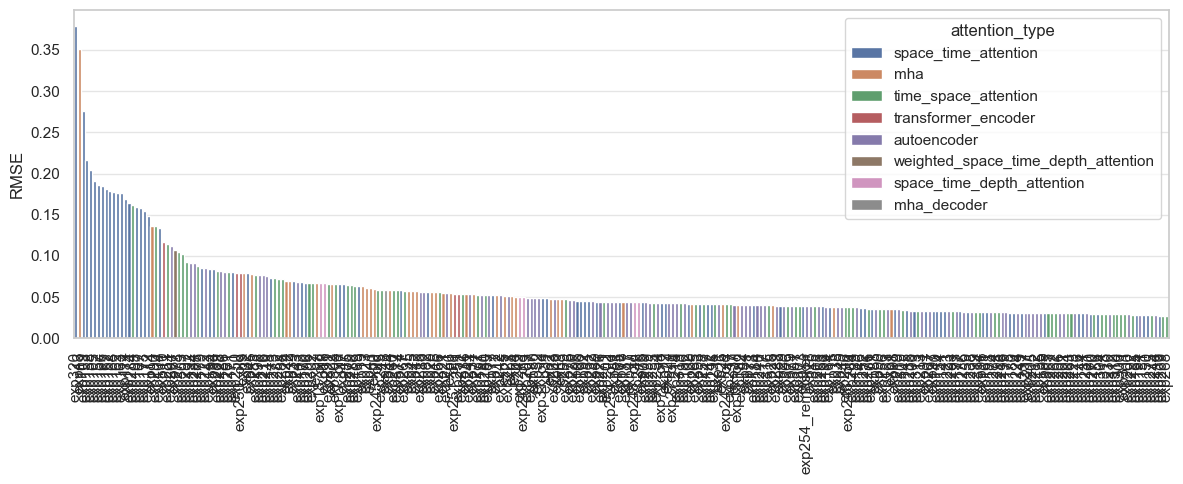

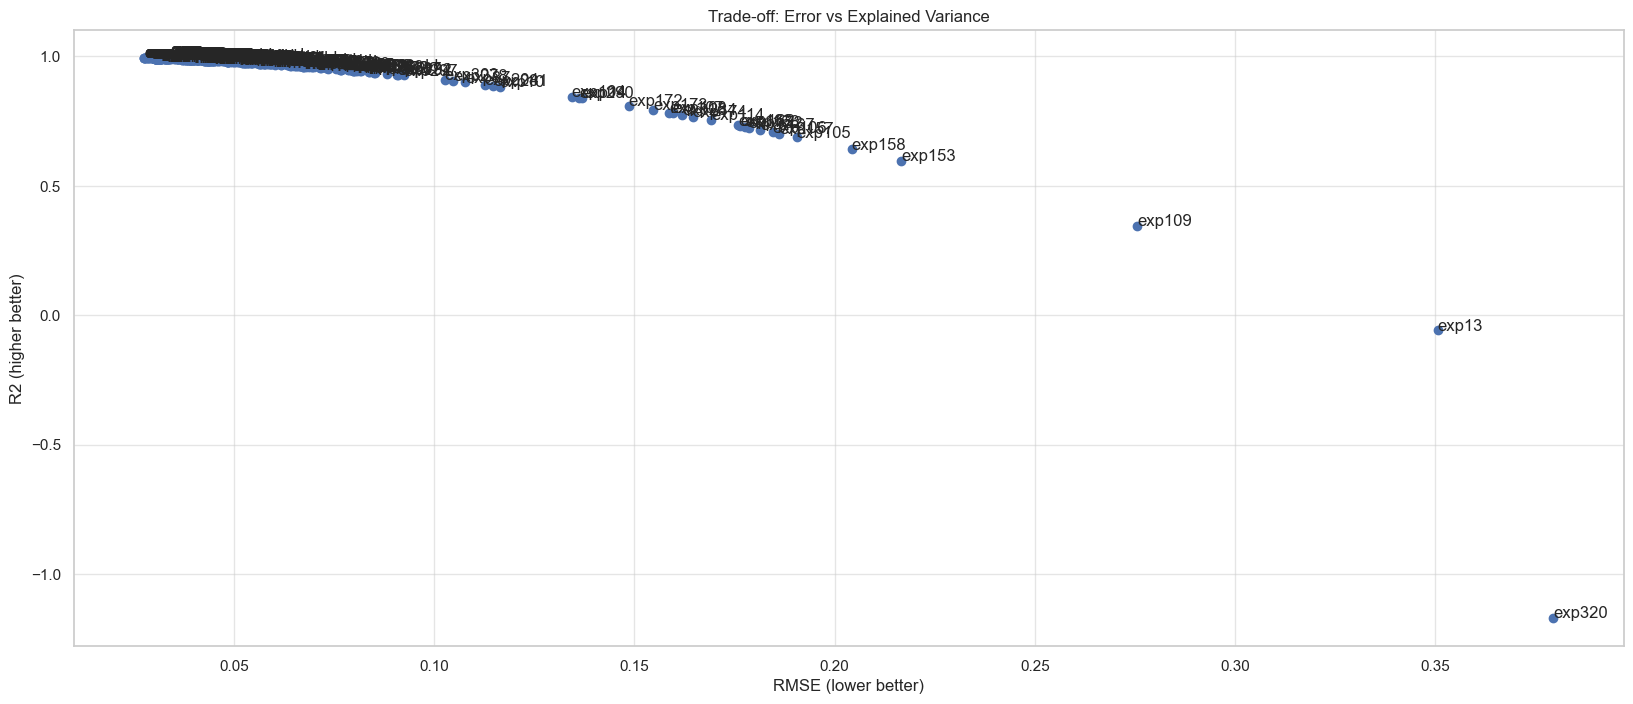

In [14]:
# Plotting
error_name = "RMSE"
temp = df_global.sort_values(error_name, ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(temp, x="exp_id", y=error_name, hue="attention_type")
plt.xticks(rotation=90)
plt.xlabel("")
plt.tight_layout()
# plt.savefig("output/plots/mastnet_ablation_rmse.png")
plt.show()

# RMSE vs R2 trade-off
error_name = "RMSE"
plt.figure(figsize=(20, 8))
plt.scatter(df_global[error_name], df_global["R2"])
for i, row in df_global.iterrows():
    plt.text(row[error_name], row["R2"], row["exp_id"])
plt.xlabel(f"{error_name} (lower better)")
plt.ylabel("R2 (higher better)")
plt.title("Trade-off: Error vs Explained Variance")
plt.show()

In [20]:
# Ranking of space-time attention experiments
min_metrics_ov = ["RMSE", "WOA_diff", "CMIP_diff"]

df_sta = df_global[df_global["attention_type"] == "space_time_attention"].copy()

ranked_sta = pd.DataFrame()
ranked_sta["exp_id"] = df_sta["exp_id"]

for min_metric in min_metrics_ov:
    if min_metric in df_sta.columns:
        ranked_sta[min_metric] = df_sta[min_metric].rank(ascending=True)

ranked_sta["total_rank"] = ranked_sta.drop(columns=["exp_id"]).mean(axis=1)
ranked_sta.sort_values("total_rank")


,exp_id,RMSE,total_rank
55,exp139,1.0,1.0
71,exp150,2.0,2.0
72,exp151,3.0,3.0
76,exp155,4.0,4.0
77,exp156,5.0,5.0
...,...,...,...
53,exp105,77.0,77.0
79,exp158,78.0,78.0
74,exp153,79.0,79.0
57,exp109,80.0,80.0


# Graph construction

Ablates the k-NN graph used to select each query point's neighbourhood. Covers: static vs. dynamic graph construction, learnable anisotropic edge weights, input encoding for the graph encoder, and update/freeze schedules for dynamic graphs.

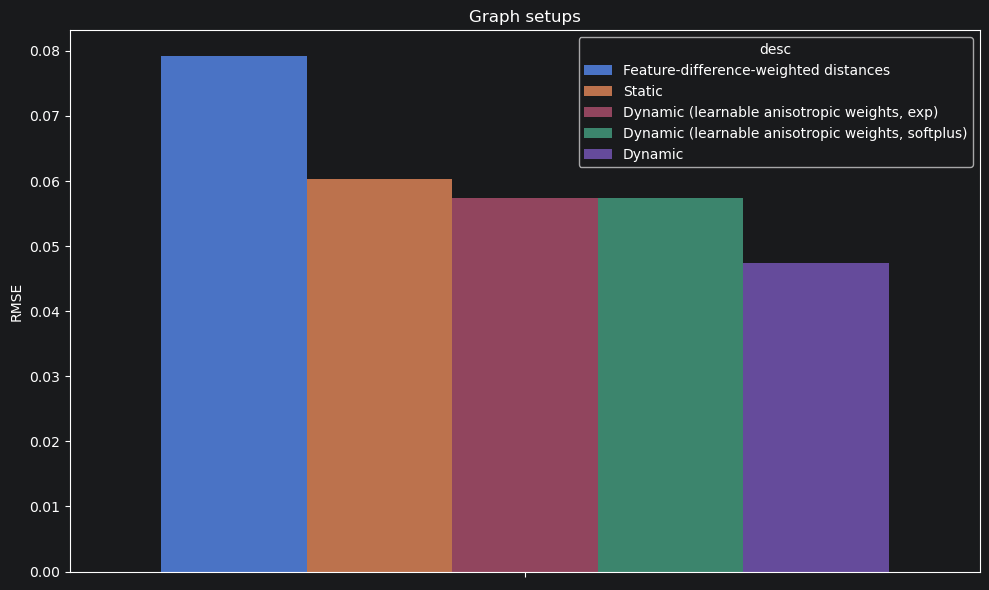

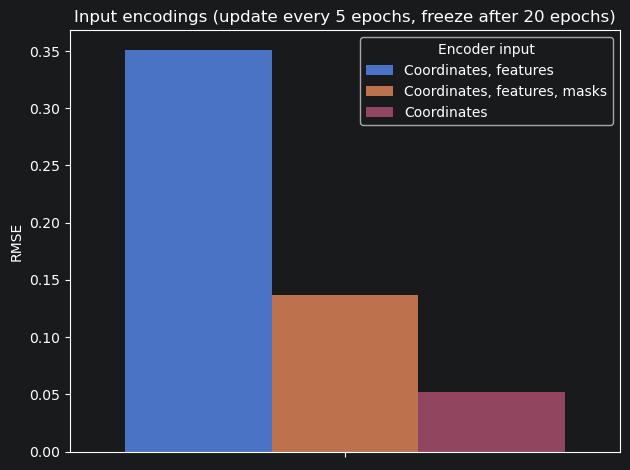

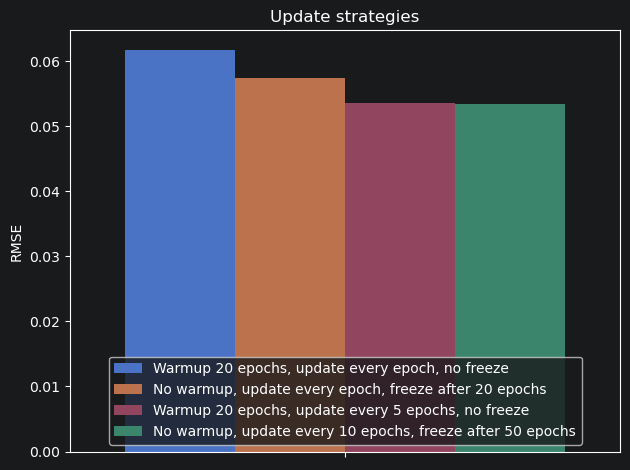

In [52]:
# KNN graph ablation
attr_list = ["graph_mode", "graph_space", "graph_metric", "graph_update_frequency",
             "graph_warmup", "graph_freeze_epoch", "learn_anisotropic_weights",
             "encoder_scope", "encoder_input"]
error_name = "RMSE"

id_desc_map = {
    0: "Static",
    9: "Feature-difference-weighted distances",
    43: "Dynamic (learnable anisotropic weights, softplus)",
    45: "Dynamic (learnable anisotropic weights, exp)",
    40: "Dynamic",
    35: "No warmup, update every epoch, freeze after 20 epochs",
    34: "No warmup, update every 10 epochs, freeze after 50 epochs",
    41: "Warmup 20 epochs, update every epoch, no freeze",
    36: "Warmup 20 epochs, update every 5 epochs, no freeze",
}

# Basic KNN setups
r1, df_woa, df_cmip = load_experiments([0, 9, 40, 45, 43], attr_list, woa=True)
t1 = r1.sort_values(error_name, ascending=False)
t1["desc"] = t1["exp_id"].map(id_desc_map)

plt.figure(figsize=(10, 6))
sns.barplot(data=t1, hue="desc", y=error_name)
plt.xlabel("")
plt.xticks(rotation=90)
plt.title("Graph setups")
plt.tight_layout()
#plt.savefig(f"{config.output_dir_plots}/ablation/mastnet_ablation_knn_graph_{error_name}.png")
plt.show()

# Input encoding
r2, df_woa, df_cmip = load_experiments([12, 13, 14], attr_list, woa=True)
t2 = r2.sort_values(error_name, ascending=False)
t2["Encoder input"] = t2["encoder_input"].map({
    "coords_feat": "Coordinates, features",
    "coords_feat_mask": "Coordinates, features, masks",
    "coords": "Coordinates"
})

sns.barplot(data=t2, hue="Encoder input", y=error_name)
plt.xlabel("")
plt.title("Input encodings (update every 5 epochs, freeze after 20 epochs)")
plt.tight_layout()
#plt.savefig(f"{config.output_dir_plots}/ablation/mastnet_ablation_knn_graph_input_encodings_{error_name}.png")
plt.show()

# Update strategies
r3, df_woa, df_cmip = load_experiments([34, 35, 36, 41], attr_list, woa=True)
t3 = r3.sort_values(error_name, ascending=False)
t3["desc"] = t3["exp_id"].map(id_desc_map)

sns.barplot(data=t3, hue="desc", y=error_name)
plt.xlabel("")
plt.title("Update strategies")
plt.legend(loc="lower center")
plt.tight_layout()
#plt.savefig(f"{config.output_dir_plots}/ablation/mastnet_ablation_knn_graph_update_strategies_{error_name}.png")
plt.show()


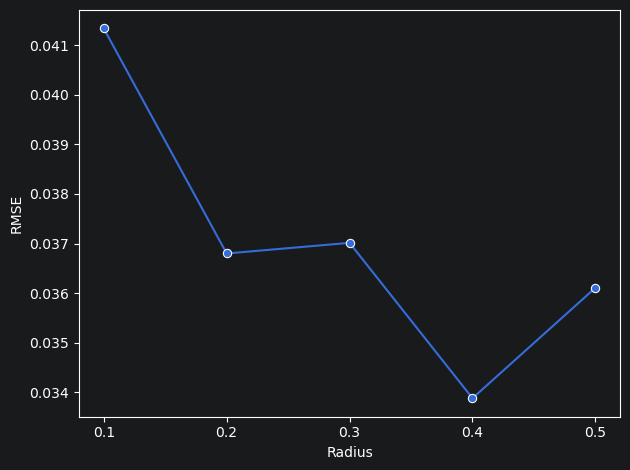

In [53]:
# Block size ablation
exp_ids = [61] + list(range(63, 67))
attr_list = ["block_mask_size"]
error_name = "RMSE"
results, df_woa, df_cmip = load_experiments(exp_ids, attr_list, woa=True)

sns.lineplot(data=results, x="block_mask_size", y=error_name, marker="o")
plt.xticks(ticks=np.sort(results["block_mask_size"].unique()))
plt.xlabel("Radius")
plt.tight_layout()
plt.savefig(f"{config.output_dir_plots}/ablation/mastnet_ablation_block_size_{error_name}.png")
plt.show()


# Neighbourhood and positional encoding

Ablates neighbourhood size (k), the use of relative position vectors in attention (i.e. whether the model sees lat, lon, depth, time to each neighbour), and strategies for encoding absolute coordinates.

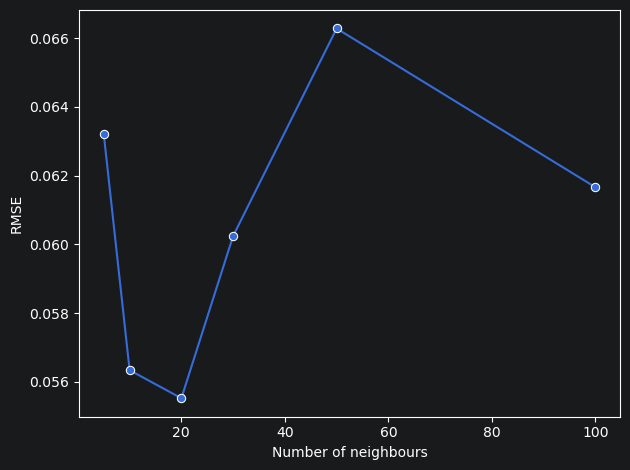

In [54]:
# Number of neighbours ablation
exp_ids = [0, 19, 20, 21, 22, 23]
attr_list = ["n_neighbours"]
error_name = "RMSE"

results, df_woa, df_cmip = load_experiments(exp_ids, attr_list, woa=True)
results = results.sort_values(error_name, ascending=False)

sns.lineplot(results, x="n_neighbours", y=error_name, marker="o")
plt.xlabel("Number of neighbours")
plt.tight_layout()
# plt.savefig(f"output/plots/ablation/mastnet_ablation_n_neighbours_{error_name}.png")
plt.show()


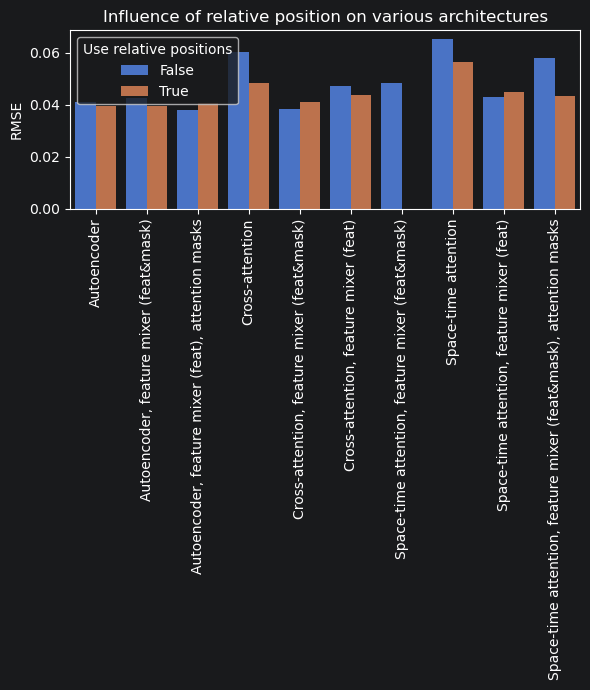

In [55]:
# Relative position encoding ablation
exp_ids = [0, 2, 15, 26, 3, 11, 27, 29, 38, 72, 78, 79, 75, 74, 81, 17, 31, 71, 82]
attr_list = ["attention_type", "feature_mixer_input", "feature_mixer", "use_masks",
             "use_rel_pos", "positional_encoding"]
error_name = "RMSE"

results, df_woa, df_cmip = load_experiments(exp_ids, attr_list, woa=True)
results = results.sort_values("attention_type")
results["model_label"] = (
        results["attention_type"] +
        np.where(results["feature_mixer"],
                 ", feature mixer (" + results["feature_mixer_input"].str.replace("_", "&") + ")", "") +
        np.where(results["use_masks"], ", attention masks", "")
)
results = results.rename(columns={"use_rel_pos": "Use relative positions"})

plt.figure(figsize=(6, 7))
sns.barplot(results, x="model_label", y=error_name, hue="Use relative positions")
plt.xlabel("")
plt.xticks(rotation=90)
plt.title("Influence of relative position on various architectures")
plt.tight_layout()
# plt.savefig(f"output/plots/ablation/mastnet_ablation_rel_pos_{error_name}.png")
plt.show()


| exp_id | Architecture | Feature mixer | Masks | Rel pos |
|--------|--------------|---------------|-------|---------|
| 0  | MHA          |               |       |         |
| 2  | MHA          |               |       | rel_pos |
| 24 | MHA          |               |       | rel_pos (encoded) |
| 26 | MHA          | feat+mask     |       | rel_pos |
| 15 | MHA          | feat+mask     |       |         |
| 78 | MHA          | feat          |       | rel_pos |
| 3  | MHA          | feat          |       |         |
| 79 | Autoencoder  |               |       | rel_pos |
| 11 | Autoencoder  |               |       |         |
| 29 | Autoencoder  | feat+mask     |       | rel_pos |
| 27 | Autoencoder  | feat+mask     |       |         |
| 71 | Autoencoder  | feat          | masks | rel_pos |
| 38 | Autoencoder  | feat          | masks |         |
| 75 | Space-time   | feat          |       | rel_pos |
| 72 | Space-time   | feat          |       |         |

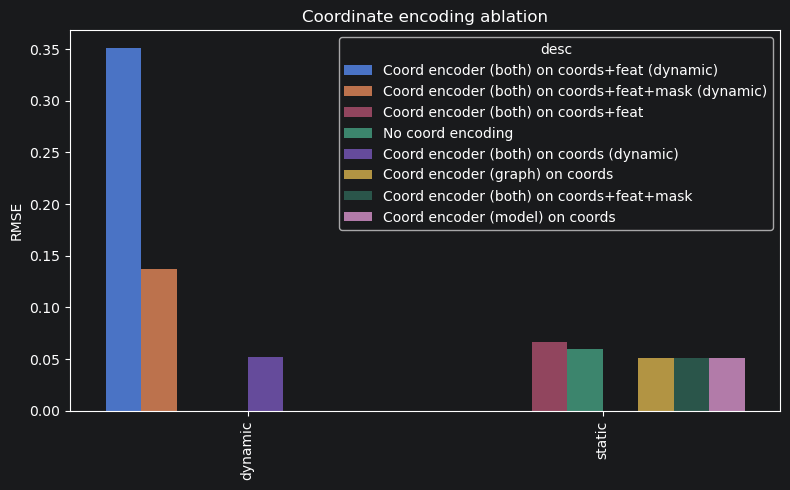

In [60]:
# Coordinate encoding ablation
exp_ids = [0, 4, 5, 7, 8, 12, 13, 14]
attr_list = ["encoder_input", "encoder_scope", "graph_mode"]
error_name = "RMSE"

results, df_woa, df_cmip = load_experiments(exp_ids, attr_list, woa=True)
results = results.sort_values(error_name, ascending=False)

results["desc"] = results["exp_id"].map({
    0: "No coord encoding",
    4: "Coord encoder (model) on coords",
    5: "Coord encoder (graph) on coords",
    7: "Coord encoder (both) on coords+feat",
    8: "Coord encoder (both) on coords+feat+mask",
    12: "Coord encoder (both) on coords (dynamic)",
    13: "Coord encoder (both) on coords+feat (dynamic)",
    14: "Coord encoder (both) on coords+feat+mask (dynamic)",
})

plt.figure(figsize=(8, 5))
sns.barplot(results, hue="desc", y=error_name, x="graph_mode")
plt.xlabel("")
plt.xticks(rotation=90)
plt.title("Coordinate encoding ablation")
plt.tight_layout()
#plt.savefig(f"output/plots/ablation/mastnet_ablation_coord_encoding_{error_name}.png")
plt.show()


# Mask information

Ablates whether missingness indicators (binary mask vectors) are fed as input features into the model and/or the feature mixer. Separates the effect of mask-aware attention from mask-aware feature mixing.

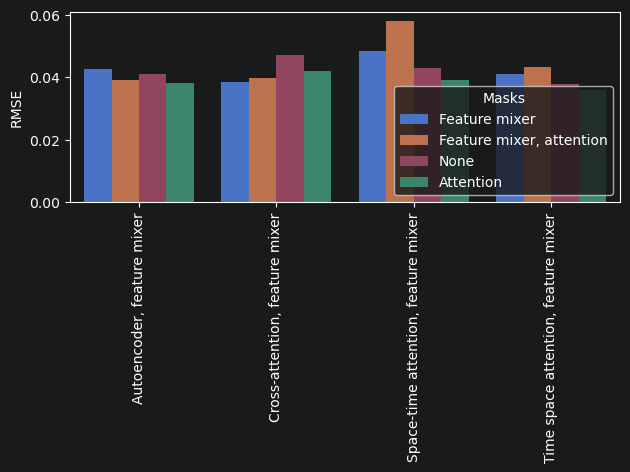

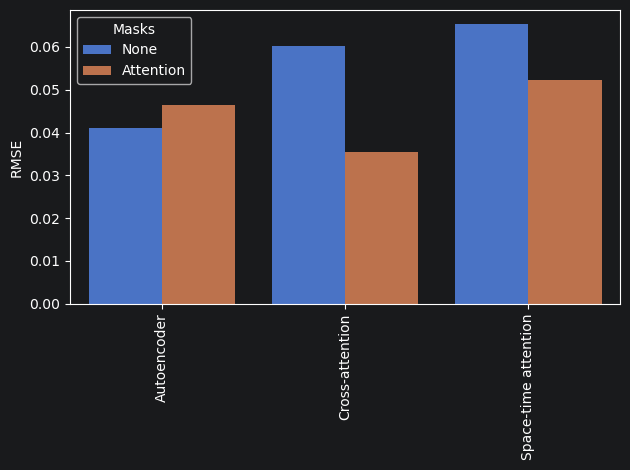

In [57]:
# Influence of mask indicators as input features
exp_ids = [0, 15, 1, 3, 30, 25, 11, 27, 28, 17, 31, 76, 74, 37, 38, 72, 73, 77,
           90, 246, 247, 255]
attr_list = ["attention_type", "feature_mixer_input", "feature_mixer", "use_masks"]
error_name = "RMSE"

results, df_woa, df_cmip = load_experiments(exp_ids, attr_list, woa=True)
results["model_label"] = results["attention_type"] + np.where(results["feature_mixer"], ", feature mixer", "")
fm = results["feature_mixer"]
fmm = results["feature_mixer_input"] == "feat_mask"
att = results["use_masks"]
results["Masks"] = np.select(
    [fmm & att & fm, fmm & fm, att],
    ["Feature mixer, attention", "Feature mixer", "Attention"],
    default="None"
)
results = results.sort_values("model_label")

sns.barplot(data=results[results["feature_mixer"]], x="model_label", hue="Masks", y=error_name)
plt.xlabel("")
plt.xticks(rotation=90)
plt.legend(loc="lower right", title="Masks")
plt.tight_layout()
# plt.savefig(f"{config.output_dir_plots}/ablation/mastnet_ablation_masks_feature_mixer_{error_name}.png")
plt.show()

sns.barplot(data=results[~results["feature_mixer"]], x="model_label", hue="Masks", y=error_name)
plt.xlabel("")
plt.xticks(rotation=90)
plt.tight_layout()
# plt.savefig(f"{config.output_dir_plots}/ablation/mastnet_ablation_masks_no_feature_mixer_{error_name}.png")
plt.show()
